# PPD-TRUST-MC

## Stage 0 — Environment and Configuration

Colab Secret not readable (SecretNotFoundError); falling back to prompt.
Paste the Prior Labs API key (from ux.priorlabs.ai/account): ··········
TabPFN authentication configured from hidden runtime prompt (length 53, fingerprint 049a47e8).
TabPFN licence + weights verified.


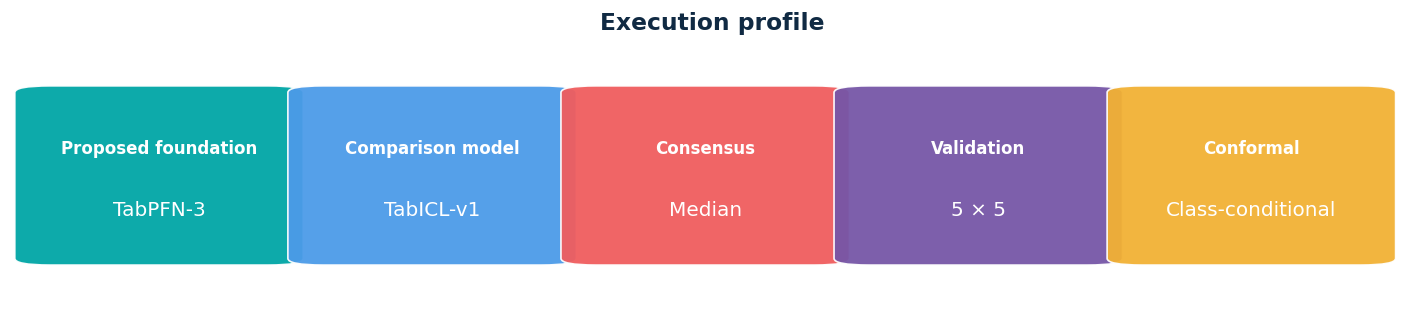

{'device': 'cuda', 'proposed_foundation': 'TabPFN-3', 'tabpfn_estimators': 16, 'tabpfn_core_estimators': 12, 'comparison_foundation': 'TabICL-v1', 'tabicl_checkpoint': 'tabicl-classifier-v1-20250208.ckpt', 'tabicl_estimators': 8, 'outer_repeats': 5, 'outer_folds': 5, 'inner_folds': 3, 'result_dir': '/content/gdrive/MyDrive/dataset/postpartum depression dataset/ppd_trust_mc_tabpfn3_fixed_median_results'}


In [ ]:
%pip -q install tabicl 'tabpfn>=8.1,<9' shap statsmodels xgboost pytorch-tabnet

import os, re, gc, json, math, time, pickle, random, hashlib, warnings, inspect, sys, urllib.parse
from pathlib import Path
from collections import OrderedDict, defaultdict
warnings.filterwarnings('ignore')

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib as mpl
from matplotlib.patches import FancyBboxPatch, FancyArrowPatch
from scipy import stats
from scipy.optimize import minimize
from IPython.display import display

import torch
import torch.nn as nn

from sklearn.base import BaseEstimator, TransformerMixin, ClassifierMixin, clone
from sklearn.model_selection import StratifiedKFold, train_test_split
from sklearn.metrics import (
    roc_auc_score, average_precision_score, brier_score_loss,
    balanced_accuracy_score, matthews_corrcoef, confusion_matrix,
    roc_curve, precision_recall_curve, log_loss
)

RANDOM_STATE = 42
np.random.seed(RANDOM_STATE)
random.seed(RANDOM_STATE)
torch.manual_seed(RANDOM_STATE)
if torch.cuda.is_available():
    torch.cuda.manual_seed_all(RANDOM_STATE)

DEVICE = 'cuda' if torch.cuda.is_available() else 'cpu'

# Results + checkpoints on Google Drive so they survive runtime resets
if Path('/content').exists():
    if not Path('/content/gdrive/MyDrive').exists():
        from google.colab import drive
        drive.mount('/content/gdrive')
    RESULT_DIR = Path('/content/gdrive/MyDrive/dataset/postpartum depression dataset/'
                      'ppd_trust_mc_tabpfn3_fixed_median_results')
else:
    RESULT_DIR = Path('ppd_trust_mc_tabpfn3_fixed_median_results')
RESULT_DIR.mkdir(parents=True, exist_ok=True)

MANUSCRIPT_RUN = True
OUTER_FOLDS = 5
OUTER_REPEATS = 5 if MANUSCRIPT_RUN else 1
INNER_FOLDS = 3
META_FOLDS = 5
SELECT_K = 64
CORE_K = 40
PHQ2_CUTOFF = 3
PHQ9_CUTOFF = 10          # PHQ-9 >= 10 : probable major depressive disorder
EPDS_CUTOFF = 13         # EPDS >= 13 : secondary probable-depression endpoint
EARLY_MONTH_MIN = 2
EARLY_MONTH_MAX = 6
N_BOOT = 2000 if MANUSCRIPT_RUN else 300
RUN_DEEP_BASELINES = True
RUN_EXTENDED_ANALYSES = True
ABLATION_REPEATS = OUTER_REPEATS if MANUSCRIPT_RUN else 1
ROBUSTNESS_SEEDS = [7, 21, 42] if MANUSCRIPT_RUN else [42]
# Reduced training budgets: each fold is cheaper, so a Colab disconnect that
# forces a rerun from Stage 0 loses far less compute (the nested-CV loop also
# checkpoints every job to RESULT_DIR and resumes automatically).
FT_EPOCHS = 40 if MANUSCRIPT_RUN else 12
TABTRANSFORMER_EPOCHS = 60 if MANUSCRIPT_RUN else 18
TABM_EPOCHS = 60 if MANUSCRIPT_RUN else 18
TABNET_EPOCHS = 60 if MANUSCRIPT_RUN else 18

TABPFN_ESTIMATORS = 16
TABPFN_CORE_ESTIMATORS = 12
TABICL_CHECKPOINT = 'tabicl-classifier-v1-20250208.ckpt'
TABICL_ESTIMATORS = 8
TABICL_BATCH_SIZE = 4 if DEVICE == 'cuda' else 2

from getpass import getpass


def configure_tabpfn_authentication():
    # Never reuse a key left in memory from an earlier run
    os.environ.pop('TABPFN_TOKEN', None)
    token, source_name = '', ''

    # 1) Colab Secrets (key icon, name exactly TABPFN_TOKEN, Notebook access ON)
    try:
        from google.colab import userdata
        token = str(userdata.get('TABPFN_TOKEN') or '').strip()
        source_name = 'Colab Secrets'
    except Exception as e:
        print(f'Colab Secret not readable ({type(e).__name__}); falling back to prompt.')
        token = ''

    # 2) Hidden prompt
    if not token:
        token = str(
            getpass(
                'Paste the Prior Labs API key (from ux.priorlabs.ai/account): '
            )
            or ''
        ).strip()
        source_name = 'hidden runtime prompt'

    if not token:
        raise RuntimeError(
            'TABPFN_TOKEN is required for TabPFN-3 local inference. '
            'Accept the model license in the Prior Labs account and rerun this cell.'
        )

    os.environ['TABPFN_TOKEN'] = token
    fp = hashlib.sha256(token.encode()).hexdigest()[:8]
    print(f'TabPFN authentication configured from {source_name} (length {len(token)}, fingerprint {fp}).')
    return True


def verify_tabpfn_license(max_attempts=5):
    """Fit a tiny TabPFN model. If the licence for the exact model is not accepted,
    print the acceptance link, wait for the user, re-check, and continue."""
    # Fresh import so the current TABPFN_TOKEN is used
    for mod in [m for m in sys.modules if m == 'tabpfn' or m.startswith('tabpfn.')]:
        del sys.modules[mod]

    import tabpfn.browser_auth as ba
    from tabpfn import TabPFNClassifier

    # Record which model repo TabPFN asks a licence for
    captured = []
    original = ba.ensure_license_accepted
    def _spy(hf_repo_id, *a, **k):
        captured.append(hf_repo_id)
        return original(hf_repo_id, *a, **k)
    for m in list(sys.modules.values()):
        if m is not None and getattr(m, '__name__', '').startswith('tabpfn') \
                and hasattr(m, 'ensure_license_accepted'):
            m.ensure_license_accepted = _spy

    rng = np.random.default_rng(0)
    Xt = rng.normal(size=(40, 4)); yt = (Xt[:, 0] > 0).astype(int)

    def _try_fit():
        try:
            TabPFNClassifier(n_estimators=1, device=DEVICE).fit(Xt, yt)
            return None
        except Exception as e:
            return e

    error = _try_fit()
    if error is None:
        print('TabPFN licence + weights verified.')
        return True

    repos = list(dict.fromkeys(captured))
    if not repos:
        raise RuntimeError('TabPFN failed before the licence check:\n' + repr(error)) from None

    gui = ba.settings.tabpfn.auth_gui_url
    api = ba.settings.tabpfn.auth_api_url
    token = os.environ['TABPFN_TOKEN']

    def _status():
        rows = []
        for repo in repos:
            lic = ba._get_license_name(repo)
            rows.append((repo, lic, ba.check_license_accepted(token, api, lic)))
        return rows

    for attempt in range(1, max_attempts + 1):
        rows = _status()
        print('\n================ TabPFN LICENCE REQUIRED ================')
        for repo, lic, ok in rows:
            print(f'model repo : {repo}')
            print(f'licence    : {lic}')
            print(f'accepted?  : {ok}')
            if ok is not True:
                print(f'ACCEPT HERE: {gui}/accept-license?hf_repo_id={urllib.parse.quote(repo)}')
            print()
        if all(ok is True for _, _, ok in rows):
            break
        print('Open the link above in your browser, logged into the Prior Labs account that owns')
        print('THIS API key, submit the acceptance form, then come back here.')
        print('=========================================================')
        reply = input(f'[{attempt}/{max_attempts}] Press Enter once accepted (or type q to stop): ').strip().lower()
        if reply == 'q':
            break

    error = _try_fit()
    if error is None:
        print('TabPFN licence + weights verified.')
        return True
    raise RuntimeError(
        'TabPFN licence still not accepted for this API key. If the acceptance page says it is '
        'already accepted, you are logged into a DIFFERENT Prior Labs account - copy the API key '
        'from ux.priorlabs.ai/account in that browser and rerun this cell.\n' + repr(error)
    ) from None


TABPFN_AUTHENTICATED = configure_tabpfn_authentication()
verify_tabpfn_license()



PRIMARY = 'PPD-TRUST-MC† (proposed)'
TABICL_BASELINE = 'TabICL-v1'
NEGATIVE_CLASS_NAME = 'no probable depression (PHQ-9 < 10)'
POSITIVE_CLASS_NAME = 'probable major depression (PHQ-9 ≥ 10)'

NAVY='#102A43'; TEAL='#00A6A6'; CORAL='#F05D5E'; GOLD='#F2B134'; PURPLE='#7656A7'; SKY='#4C9BE8'; GREY='#8293A4'; GREEN='#2CA58D'
PALETTE=[TEAL,SKY,CORAL,GOLD,PURPLE,GREEN,'#D1495B','#577590','#F9844A']
mpl.rcParams.update({
    'figure.facecolor':'white','axes.facecolor':'#F8FAFC','axes.edgecolor':'#D7E0E8',
    'axes.grid':True,'grid.color':'#E5ECF2','grid.linewidth':0.8,
    'axes.titleweight':'bold','axes.titlecolor':NAVY,'axes.titlesize':14,
    'axes.labelcolor':'#334E68','font.size':11,'savefig.dpi':190,'figure.dpi':120,
    'legend.frameon':True,'legend.framealpha':.92
})

def save_show(fig, name):
    fig.tight_layout()
    fig.savefig(RESULT_DIR / f'{name}.png', bbox_inches='tight')
    plt.show()

def styled_table(frame, gradient=None, precision=4):
    styler = frame.style.format(precision=precision).set_properties(**{'text-align':'center'})
    if gradient and gradient in frame.columns:
        styler = styler.background_gradient(subset=[gradient], cmap='YlGnBu')
    return styler

fig, ax = plt.subplots(figsize=(12, 2.8))
ax.axis('off')
items = [
    ('Proposed foundation', 'TabPFN-3', TEAL),
    ('Comparison model', 'TabICL-v1', SKY),
    ('Consensus', 'Median', CORAL),
    ('Validation', f'{OUTER_REPEATS} × {OUTER_FOLDS}', PURPLE),
    ('Conformal', 'Class-conditional', GOLD),
]
for i, (label, value, color) in enumerate(items):
    x = .02 + i * .195
    box = FancyBboxPatch((x, .18), .17, .64, boxstyle='round,pad=0.018,rounding_size=0.025',
                         facecolor=color, edgecolor='white', alpha=.95, transform=ax.transAxes)
    ax.add_patch(box)
    ax.text(x+.085, .60, label, ha='center', va='center', color='white', weight='bold', fontsize=10, transform=ax.transAxes)
    ax.text(x+.085, .37, value, ha='center', va='center', color='white', fontsize=12, transform=ax.transAxes)
ax.set_title('Execution profile', pad=8)
save_show(fig, 'stage00_execution_profile')

print({
    'device': DEVICE,
    'proposed_foundation': 'TabPFN-3',
    'tabpfn_estimators': TABPFN_ESTIMATORS,
    'tabpfn_core_estimators': TABPFN_CORE_ESTIMATORS,
    'comparison_foundation': TABICL_BASELINE,
    'tabicl_checkpoint': TABICL_CHECKPOINT,
    'tabicl_estimators': TABICL_ESTIMATORS,
    'outer_repeats': OUTER_REPEATS,
    'outer_folds': OUTER_FOLDS,
    'inner_folds': INNER_FOLDS,
    'result_dir': str(RESULT_DIR),
})

## Stage 1 — Dataset Assembly

Primary cohort : /content/data/PPD_dataset_v2.csv -> (800, 51)
External cohort: /content/data/LTM III national.tab


,Dataset,Available,Records
0,"PPD_dataset_v2 (primary, PHQ-9)",True,800
1,LTM III national (external screen),True,2400


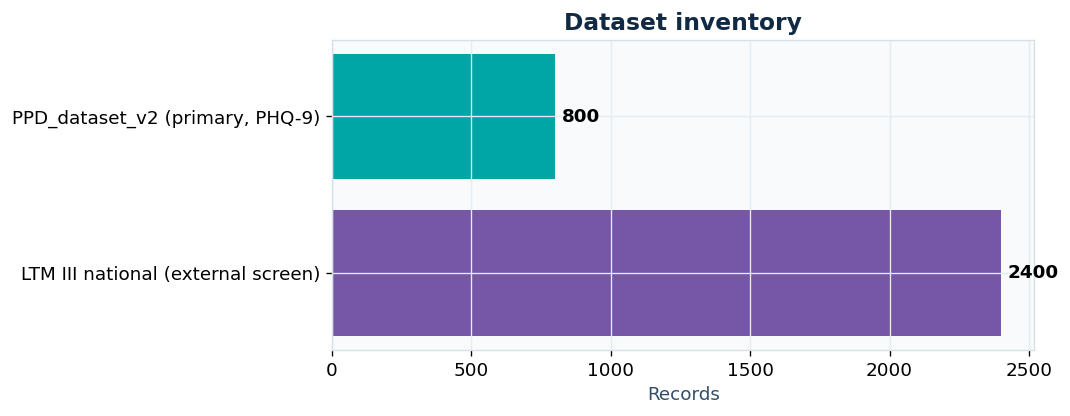

In [ ]:
# Primary cohort: PPD_dataset_v2.csv (Bangladesh, N=800, diagnostic-grade PHQ-9/EPDS).
# External cohort: LTM III national (US) for harmonized cross-national transportability.
import shutil
from pathlib import Path
import pandas as pd
import matplotlib.pyplot as plt

if not Path('/content/gdrive/MyDrive').exists():
    from google.colab import drive
    drive.mount('/content/gdrive')

BASE = Path('/content/gdrive/MyDrive/dataset/postpartum depression dataset')
DRIVE_DIRS = [
    BASE / 'Postpartum Depression Bangladesh',   # PPD_dataset_v2.csv
    BASE,                                        # LTM III national.tab
]
LOCAL_DIR = Path('/content/data')
LOCAL_DIR.mkdir(exist_ok=True)

def _resolve_path(*names):
    # 1) local cache first (instant on re-runs)
    for n in names:
        if (LOCAL_DIR / n).exists():
            return LOCAL_DIR / n
    # 2) known Drive folders only, never a recursive crawl
    for d in DRIVE_DIRS:
        for n in names:
            src = d / n
            if src.exists():
                dst = LOCAL_DIR / n
                shutil.copy(src, dst)   # one-time copy to fast local disk
                return dst
    return None

PRIMARY_PATH  = _resolve_path('PPD_dataset_v2.csv')
NATIONAL_PATH = _resolve_path('LTM III national.tab', 'LTM_III_national.tab')
if PRIMARY_PATH is None:
    raise FileNotFoundError('PPD_dataset_v2.csv not found in: ' + ', '.join(map(str, DRIVE_DIRS)))

df = pd.read_csv(PRIMARY_PATH, low_memory=False)
national_available = NATIONAL_PATH is not None
print('Primary cohort :', PRIMARY_PATH, '->', df.shape)
print('External cohort:', NATIONAL_PATH if national_available else 'NOT FOUND (external validation will be skipped)')

def _count_rows(p):
    with open(p, 'rb') as f:
        return sum(chunk.count(b'\n') for chunk in iter(lambda: f.read(1 << 20), b'')) - 1

inventory = pd.DataFrame({
    'Dataset': ['PPD_dataset_v2 (primary, PHQ-9)', 'LTM III national (external screen)'],
    'Available': [True, national_available],
    'Records': [len(df), _count_rows(NATIONAL_PATH) if national_available else 0],
})
display(styled_table(inventory, 'Records', 0))

fig, ax = plt.subplots(figsize=(9, 3.6))
bars = ax.barh(inventory.Dataset, inventory.Records, color=[TEAL, PURPLE])
ax.bar_label(bars, fmt='%.0f', padding=4, weight='bold')
ax.set(xlabel='Records', title='Dataset inventory')
ax.invert_yaxis()
save_show(fig, 'stage01_dataset_inventory')

## Stage 2 — Target Definition and Leakage Audit

,Item,Value
0,Participants,800.0000
1,PHQ-9+ (>=10),458.0000
2,PHQ-9 prevalence,0.5725
3,EPDS+ (>=13),349.0000
4,EPDS prevalence,0.4363
5,Predictors,46.0000


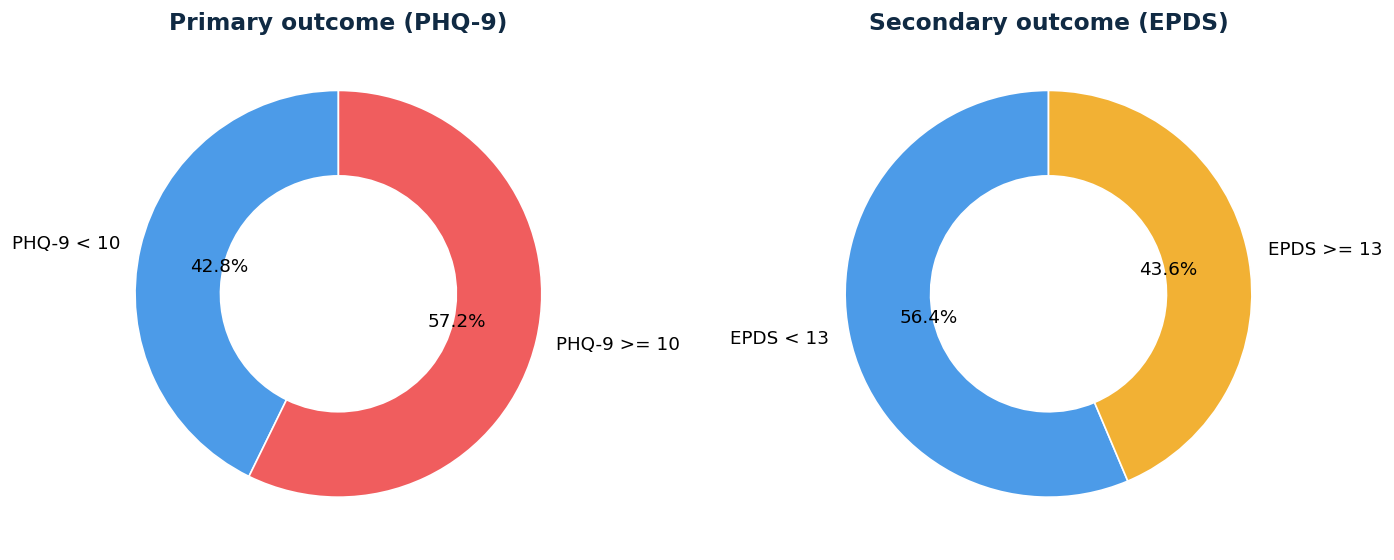

In [ ]:
# Diagnostic-grade target: PHQ-9 >= 10 (probable major depressive disorder).
# EPDS >= 13 is retained as an independent secondary endpoint for sensitivity analysis.
phq9_score = pd.to_numeric(df['PHQ9 Score'], errors='coerce')
epds_score = pd.to_numeric(df['EPDS Score'], errors='coerce')
valid_target = phq9_score.notna()
df = df.loc[valid_target].reset_index(drop=True)
phq9_score = phq9_score.loc[valid_target].reset_index(drop=True)
epds_score = epds_score.loc[valid_target].reset_index(drop=True)

y = (phq9_score >= PHQ9_CUTOFF).astype(np.int8).to_numpy()
y_epds = (epds_score >= EPDS_CUTOFF).astype(np.int8).to_numpy()
survey_weight = np.ones(len(y), dtype=float)   # PPD_dataset_v2 carries no survey weights

# Leakage audit: the two instruments measure the same postpartum episode, so every
# derivative of PHQ-9 and EPDS must be removed from the predictors. The two PHQ-2 items
# (before / during pregnancy) are temporally PRIOR and remain legitimate predictors.
LEAKAGE_COLS = ['sr', 'PHQ9 Score', 'PHQ9 Result', 'EPDS Score', 'EPDS Result']
# Affective items recorded for the current postpartum period; kept as clinically
# meaningful risk indicators. Set DROP_PROXIMAL_AFFECT=True for a strict sensitivity run.
PROXIMAL_AFFECT = ['Feeling about motherhood', 'Angry after latest child birth',
                   'Feeling for regular activities']
DROP_PROXIMAL_AFFECT = False

drop_cols = list(LEAKAGE_COLS) + (PROXIMAL_AFFECT if DROP_PROXIMAL_AFFECT else [])
X = df.drop(columns=[c for c in drop_cols if c in df.columns]).copy()
for banned in ['PHQ9 Score', 'EPDS Score', 'PHQ9 Result', 'EPDS Result']:
    if banned in X.columns:
        raise RuntimeError('Outcome leakage detected')
if len(np.unique(y)) != 2:
    raise ValueError('Both outcome classes are required')

summary = pd.DataFrame({
    'Item': ['Participants', 'PHQ-9+ (>=10)', 'PHQ-9 prevalence',
             'EPDS+ (>=13)', 'EPDS prevalence', 'Predictors'],
    'Value': [len(y), int(y.sum()), float(y.mean()),
              int(y_epds.sum()), float(y_epds.mean()), X.shape[1]],
})
display(styled_table(summary, precision=4))

fig, axes = plt.subplots(1, 2, figsize=(12, 4.8))
axes[0].pie([int((1 - y).sum()), int(y.sum())],
            labels=['PHQ-9 < 10', 'PHQ-9 >= 10'], autopct='%1.1f%%', startangle=90,
            colors=[SKY, CORAL], wedgeprops={'width': .42, 'edgecolor': 'white'})
axes[0].set_title('Primary outcome (PHQ-9)')
axes[1].pie([int((1 - y_epds).sum()), int(y_epds.sum())],
            labels=['EPDS < 13', 'EPDS >= 13'], autopct='%1.1f%%', startangle=90,
            colors=[SKY, GOLD], wedgeprops={'width': .42, 'edgecolor': 'white'})
axes[1].set_title('Secondary outcome (EPDS)')
save_show(fig, 'stage02_target_definition')


## Stage 3 — Leakage-Safe Feature Representation

,Feature,Missing,Unique,Type
15,Number of household members,1.0000,0,Categorical
10,Addiction,0.9862,3,Categorical
13,History of pregnancy loss,0.7662,3,Categorical
12,Disease before pregnancy,0.7350,3,Categorical
7,Current monthly income,0.6562,5,Categorical
33,Age of immediate older children,0.6462,4,Categorical
5,Monthly income before latest pregnancy,0.5463,5,Categorical
31,Diseases during pregnancy,0.4637,4,Categorical
43,Feeling for regular activities,0.2787,3,Categorical
22,Need for Support,0.2087,3,Categorical


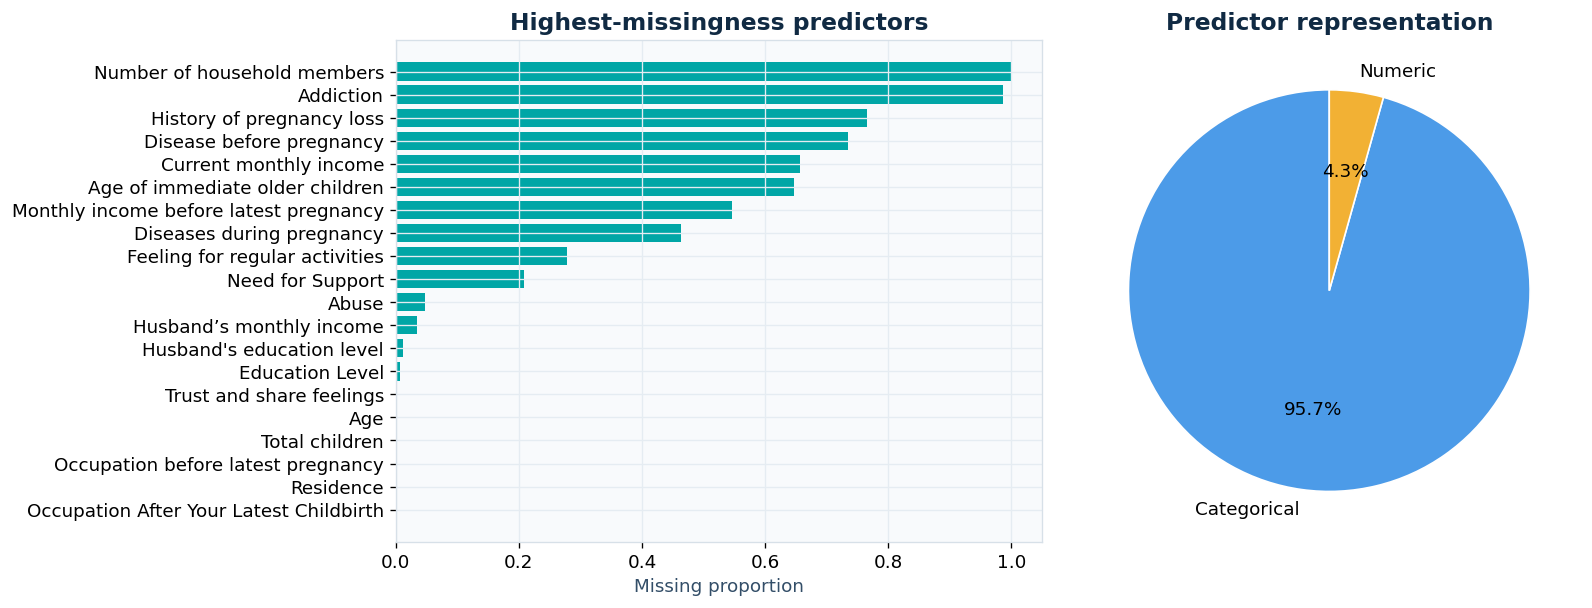

In [ ]:
# 'Age' and 'Number of the latest pregnancy' are the genuine numeric predictors;
# the remaining fields are ordinal or nominal categories handled natively by the encoders.
CONTINUOUS_COLUMNS = {'Age', 'Number of the latest pregnancy', 'Number of household members'}

def engineer_features(frame):
    out = frame.copy()
    for column in out.columns:
        numeric = pd.to_numeric(out[column], errors='coerce')
        if column in CONTINUOUS_COLUMNS:
            out[column] = numeric
        elif numeric.notna().mean() >= .80 and numeric.nunique(dropna=True) <= 20:
            out[column] = numeric.map(lambda value: '__missing__' if pd.isna(value) else f'code_{int(value)}')
    return out

Xm = engineer_features(X)
feature_profile = pd.DataFrame({
    'Feature': Xm.columns,
    'Missing': Xm.isna().mean().values,
    'Unique': [Xm[c].nunique(dropna=True) for c in Xm.columns],
    'Type': ['Numeric' if pd.to_numeric(Xm[c], errors='coerce').notna().mean() >= .80 else 'Categorical' for c in Xm.columns],
}).sort_values('Missing', ascending=False)
display(styled_table(feature_profile.head(25), 'Missing', 4))

fig, axes = plt.subplots(1, 2, figsize=(14, 5.2))
top = feature_profile.head(20).sort_values('Missing')
axes[0].barh(top.Feature, top.Missing, color=TEAL)
axes[0].set(xlabel='Missing proportion', title='Highest-missingness predictors')
type_counts = feature_profile.Type.value_counts()
axes[1].pie(type_counts.values, labels=type_counts.index, autopct='%1.1f%%',
            colors=[SKY,GOLD], startangle=90, wedgeprops={'edgecolor':'white'})
axes[1].set_title('Predictor representation')
save_show(fig, 'stage03_feature_representation')

## Stage 4 — Clinical Feature Domains

,Domain,Features
1,Pregnancy and obstetric history,13
0,Infant and postpartum care,12
4,Sociodemographic and economic,11
3,Psychosocial and relational,8
2,Prior and proximal affect,2


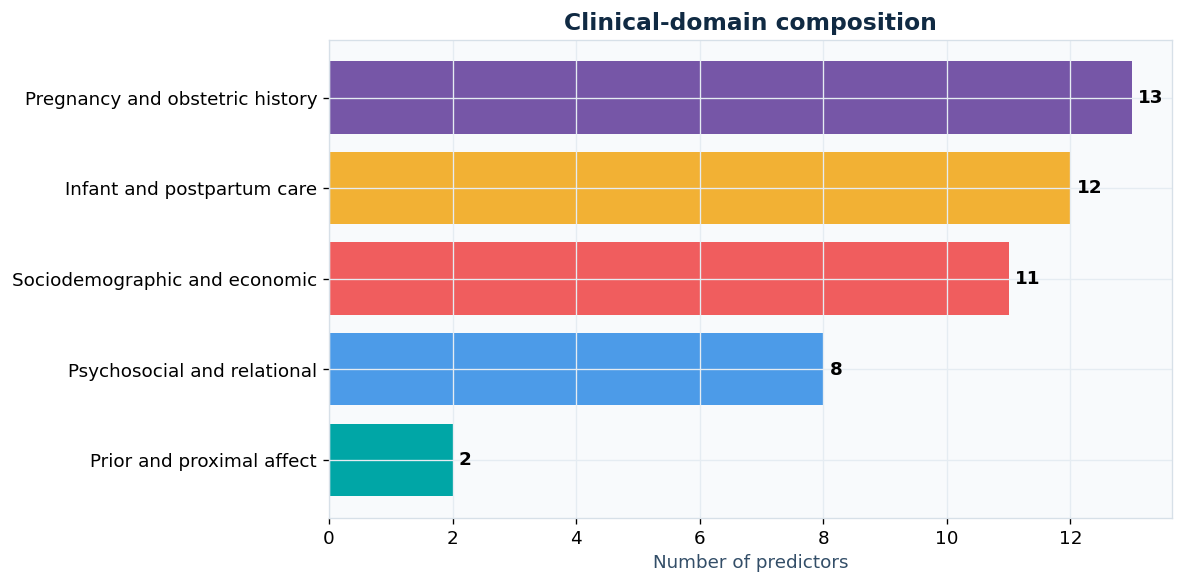

In [ ]:
# Clinical-domain assignment for the named PPD_dataset_v2 predictors. The proposed
# model consumes these domains for its counterfactual domain-shift reliability signal.
def infer_clinical_domains(columns):
    domains = defaultdict(list)
    for column in columns:
        text = str(column).lower()
        if any(k in text for k in ['age of newborn', 'age of immediate', 'newborn', 'breastfeed',
                                   'gender of', 'relax/sleep', 'worry about', 'birth compliancy',
                                   'mode of delivery', 'relationship with the newborn',
                                   'relationship between father']):
            domain = 'Infant and postpartum care'
        elif any(k in text for k in ['pregnancy', 'checkup', 'fear of', 'diseases during',
                                     'disease before', 'history of pregnancy loss']):
            domain = 'Pregnancy and obstetric history'
        elif any(k in text for k in ['relationship with the in-laws', 'relationship with husband',
                                     'support', 'abuse', 'trust and share', 'major changes',
                                     'feeling about motherhood', 'addiction']):
            domain = 'Psychosocial and relational'
        elif any(k in text for k in ['depression', 'angry after', 'feeling for regular']):
            domain = 'Prior and proximal affect'
        elif any(k in text for k in ['age', 'residence', 'education', 'marital', 'occupation',
                                     'income', 'husband', 'family type', 'household', 'children']):
            domain = 'Sociodemographic and economic'
        else:
            domain = 'Other maternal context'
        domains[domain].append(column)
    return OrderedDict((k, v) for k, v in sorted(domains.items()) if len(v) > 0)

CLINICAL_DOMAINS = infer_clinical_domains(Xm.columns)
domain_table = pd.DataFrame({'Domain': list(CLINICAL_DOMAINS),
                             'Features': [len(v) for v in CLINICAL_DOMAINS.values()]})
display(styled_table(domain_table.sort_values('Features', ascending=False), 'Features', 0))

fig, ax = plt.subplots(figsize=(10, 5.0))
plot_data = domain_table.sort_values('Features')
ax.barh(plot_data.Domain, plot_data.Features, color=PALETTE[:len(plot_data)])
ax.set(xlabel='Number of predictors', title='Clinical-domain composition')
for patch in ax.patches:
    ax.text(patch.get_width() + .1, patch.get_y() + patch.get_height() / 2,
            f'{int(patch.get_width())}', va='center', weight='bold')
save_show(fig, 'stage04_clinical_domains')


## Stage 5 — Comparator Model Library

,Model,Configuration,Calibration
0,PPD-TRUST-MC,TabPFN-3 median consensus + conformal triage,Nested
1,TabICL-v1,8 estimators,Cross-fitted
2,FT-Transformer,40 epochs,Sigmoid CV
3,TabNet,Early stopping,Sigmoid CV
4,TabTransformer,60 epochs,Sigmoid CV
5,TabM,k=32 efficient ensemble,Sigmoid CV
6,XGBoost,450 trees,Sigmoid CV
7,Penalized logistic regression,L2,Sigmoid CV


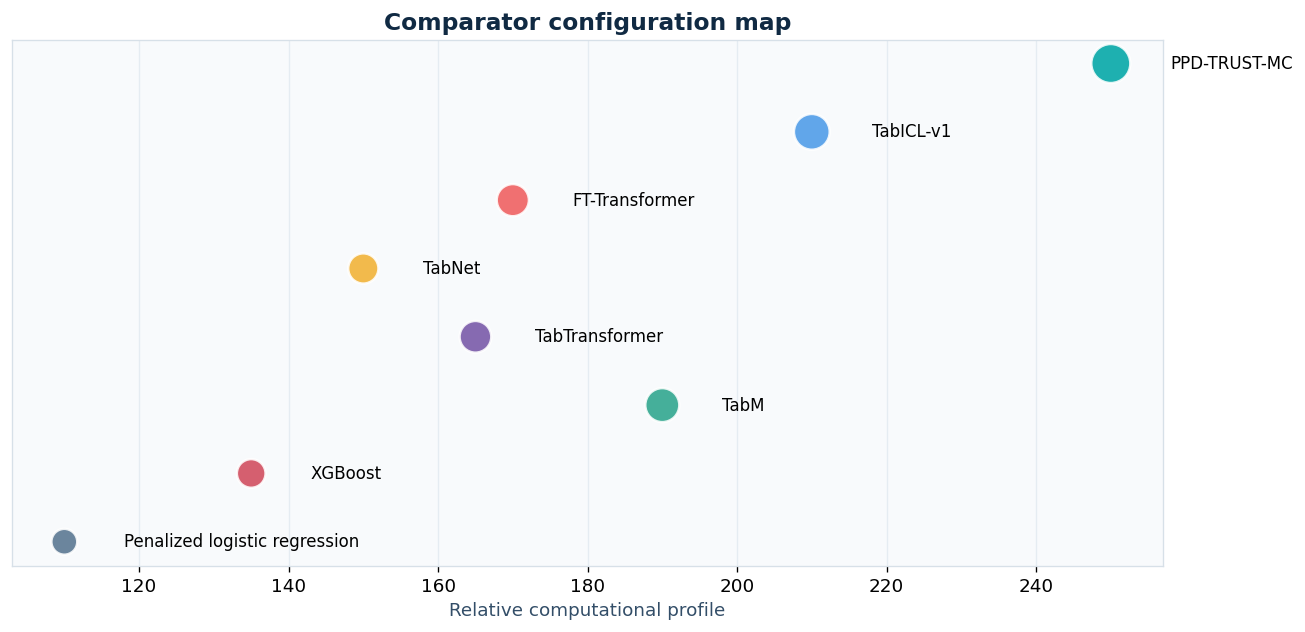

Comparator library ready


In [ ]:
from sklearn.base import BaseEstimator, TransformerMixin, ClassifierMixin, clone
from sklearn.ensemble import HistGradientBoostingClassifier
from sklearn.feature_selection import SelectKBest, mutual_info_classif
from sklearn.pipeline import Pipeline
from sklearn.calibration import CalibratedClassifierCV
from sklearn.model_selection import StratifiedKFold, train_test_split
from sklearn.metrics import (roc_auc_score, average_precision_score, brier_score_loss,
                             balanced_accuracy_score, matthews_corrcoef, confusion_matrix,
                             roc_curve, precision_recall_curve)

class TabularPreprocessor(TransformerMixin,BaseEstimator):
    """Fold-fitted numeric scaling plus bounded one/multi-hot vocabularies."""
    def __init__(self,max_levels=20): self.max_levels=max_levels
    def fit(self,X,y=None):
        X=pd.DataFrame(X).reset_index(drop=True)
        self.num_={}; self.cat_=[]; self.multi_=[]; self.numcols_=[]
        for c in X.columns:
            v=pd.to_numeric(X[c],errors="coerce")
            if v.notna().mean()>=.8:
                self.numcols_.append(c); self.num_[c]=(np.nanmedian(v),np.nanstd(v)+1e-9)
            elif X[c].astype(str).str.contains(",").any():
                vocab=pd.Series([t.strip() for row in X[c].dropna().astype(str) for t in row.split(",")]).value_counts()
                self.multi_.append((c,list(vocab.index[:self.max_levels])))
            else:
                vocab=X[c].astype(str).fillna("__miss").value_counts()
                self.cat_.append((c,list(vocab.index[:self.max_levels])))
        names=list(self.numcols_)
        for c,vs in self.cat_: names += [f"{c}={v}" for v in vs]
        for c,vs in self.multi_: names += [f"{c}::{v}" for v in vs]
        self.feature_names_=names; return self
    def transform(self,X):
        X=pd.DataFrame(X).reset_index(drop=True); blocks=[]
        for c in self.numcols_:
            med,sd=self.num_[c]; v=pd.to_numeric(X[c],errors="coerce").fillna(med)
            blocks.append(((v-med)/sd).values.reshape(-1,1))
        for c,vs in self.cat_:
            s=X[c].astype(str); blocks.append(np.stack([(s==v).astype(float).values for v in vs],axis=1))
        for c,vs in self.multi_:
            toks=X[c].astype(str).fillna("").apply(lambda r:set(t.strip() for t in r.split(",")))
            blocks.append(np.stack([toks.apply(lambda st:float(v in st)).values for v in vs],axis=1))
        return np.hstack(blocks) if blocks else np.zeros((len(X),0))

class SafeSelectK(SelectKBest):
    def fit(self,X,y=None):
        if isinstance(self.k,int): self.k=min(self.k,X.shape[1])
        return super().fit(X,y)

class _FTNet(nn.Module):
    def __init__(self,n_features,d=40,heads=4,layers=3,drop=.12):
        super().__init__(); self.W=nn.Parameter(torch.randn(n_features,d)*.02); self.b=nn.Parameter(torch.zeros(n_features,d))
        self.cls=nn.Parameter(torch.randn(1,1,d)*.02)
        layer=nn.TransformerEncoderLayer(d,heads,dim_feedforward=2*d,dropout=drop,batch_first=True,activation="gelu")
        self.encoder=nn.TransformerEncoder(layer,layers); self.norm=nn.LayerNorm(d); self.head=nn.Linear(d,2)
    def forward(self,x):
        tokens=x.unsqueeze(-1)*self.W+self.b
        z=torch.cat([self.cls.expand(x.size(0),-1,-1),tokens],1)
        return self.head(self.norm(self.encoder(z)[:,0]))

class FTTransformerSklearn(ClassifierMixin,BaseEstimator):
    _estimator_type="classifier"
    def __init__(self,d=40,heads=4,layers=3,drop=.12,epochs=80,lr=9e-4,batch=64,patience=12,seed=42):
        self.d=d; self.heads=heads; self.layers=layers; self.drop=drop; self.epochs=epochs
        self.lr=lr; self.batch=batch; self.patience=patience; self.seed=seed
    def fit(self,X,y):
        torch.manual_seed(self.seed); X=np.asarray(X,np.float32); y=np.asarray(y).astype(int); self.classes_=np.array([0,1])
        Xtr,Xva,ytr,yva=train_test_split(X,y,test_size=.16,stratify=y,random_state=self.seed)
        self.net_=_FTNet(X.shape[1],self.d,self.heads,self.layers,self.drop).to(DEVICE)
        opt=torch.optim.AdamW(self.net_.parameters(),lr=self.lr,weight_decay=1e-4)
        lossf=nn.CrossEntropyLoss(); Xt=torch.tensor(Xtr,device=DEVICE); yt=torch.tensor(ytr,device=DEVICE); Xv=torch.tensor(Xva,device=DEVICE)
        best=-1; bad=0; state=None
        for _ in range(self.epochs):
            self.net_.train(); order=torch.randperm(len(Xt),device=DEVICE)
            for start in range(0,len(Xt),self.batch):
                ix=order[start:start+self.batch]; loss=lossf(self.net_(Xt[ix]),yt[ix]); opt.zero_grad(); loss.backward(); opt.step()
            self.net_.eval()
            with torch.no_grad(): pv=torch.softmax(self.net_(Xv),1)[:,1].cpu().numpy()
            score=average_precision_score(yva,pv)
            if score>best+1e-4: best,bad=score,0; state={k:v.detach().cpu().clone() for k,v in self.net_.state_dict().items()}
            else:
                bad+=1
                if bad>=self.patience: break
        if state: self.net_.load_state_dict(state)
        return self
    def predict_proba(self,X):
        self.net_.eval()
        with torch.no_grad(): return torch.softmax(self.net_(torch.tensor(np.asarray(X,np.float32),device=DEVICE)),1).cpu().numpy()
    def predict(self,X): return (self.predict_proba(X)[:,1]>=.5).astype(int)


class TabNetSklearn(ClassifierMixin,BaseEstimator):
    """TabNet comparator with an internal early-stopping split."""
    _estimator_type="classifier"
    def __init__(self,n_d=24,n_a=24,n_steps=5,gamma=1.4,lambda_sparse=1e-4,
                 epochs=120,patience=18,batch=256,virtual_batch=64,lr=2e-2,seed=42):
        self.n_d=n_d; self.n_a=n_a; self.n_steps=n_steps; self.gamma=gamma
        self.lambda_sparse=lambda_sparse; self.epochs=epochs; self.patience=patience
        self.batch=batch; self.virtual_batch=virtual_batch; self.lr=lr; self.seed=seed

    def fit(self,X,y):
        from pytorch_tabnet.tab_model import TabNetClassifier
        torch.manual_seed(self.seed); np.random.seed(self.seed)
        X=np.asarray(X,np.float32); y=np.asarray(y).astype(int); self.classes_=np.array([0,1])
        Xtr,Xva,ytr,yva=train_test_split(X,y,test_size=.18,stratify=y,random_state=self.seed)
        device_name="cuda" if torch.cuda.is_available() else "cpu"
        self.model_=TabNetClassifier(
            n_d=self.n_d,n_a=self.n_a,n_steps=self.n_steps,gamma=self.gamma,
            lambda_sparse=self.lambda_sparse,optimizer_fn=torch.optim.Adam,
            optimizer_params={"lr":self.lr},mask_type="entmax",seed=self.seed,
            verbose=0,device_name=device_name,
        )
        batch_size=max(32,min(self.batch,len(Xtr)))
        virtual_batch_size=max(16,min(self.virtual_batch,batch_size))
        self.model_.fit(
            Xtr,ytr,eval_set=[(Xva,yva)],eval_name=["valid"],eval_metric=["auc"],
            max_epochs=self.epochs,patience=self.patience,batch_size=batch_size,
            virtual_batch_size=virtual_batch_size,num_workers=0,drop_last=False,
            weights=1,
        )
        return self

    def predict_proba(self,X):
        return self.model_.predict_proba(np.asarray(X,np.float32))

    def predict(self,X):
        return self.model_.predict(np.asarray(X,np.float32)).astype(int)


class _QuantileTabTransformerNet(nn.Module):
    """Feature-wise quantile embeddings followed by contextual self-attention."""
    def __init__(self,n_features,n_bins=16,d=48,heads=4,layers=3,drop=.15):
        super().__init__()
        self.n_features=n_features; self.n_bins=n_bins
        self.register_buffer("offsets",torch.arange(n_features,dtype=torch.long)*n_bins)
        self.bin_embedding=nn.Embedding(n_features*n_bins,d)
        self.feature_embedding=nn.Parameter(torch.randn(1,n_features,d)*.02)
        self.cls=nn.Parameter(torch.randn(1,1,d)*.02)
        layer=nn.TransformerEncoderLayer(
            d_model=d,nhead=heads,dim_feedforward=4*d,dropout=drop,
            batch_first=True,activation="gelu",norm_first=True,
        )
        self.encoder=nn.TransformerEncoder(layer,num_layers=layers)
        self.norm=nn.LayerNorm(d)
        self.head=nn.Sequential(
            nn.Linear(d,2*d),nn.GELU(),nn.Dropout(drop),nn.Linear(2*d,1)
        )

    def forward(self,bin_ids):
        token_ids=bin_ids.long()+self.offsets.unsqueeze(0)
        tokens=self.bin_embedding(token_ids)+self.feature_embedding
        cls=self.cls.expand(bin_ids.size(0),-1,-1)
        encoded=self.encoder(torch.cat([cls,tokens],dim=1))
        return self.head(self.norm(encoded[:,0])).squeeze(-1)


class TabTransformerSklearn(ClassifierMixin,BaseEstimator):
    """Leakage-safe quantile-token TabTransformer with AUPRC early stopping."""
    _estimator_type="classifier"
    def __init__(self,n_bins=16,d=48,heads=4,layers=3,drop=.15,epochs=120,
                 lr=8e-4,batch=64,patience=16,weight_decay=2e-4,seed=42):
        self.n_bins=n_bins; self.d=d; self.heads=heads; self.layers=layers
        self.drop=drop; self.epochs=epochs; self.lr=lr; self.batch=batch
        self.patience=patience; self.weight_decay=weight_decay; self.seed=seed

    def _fit_bin_edges(self,X):
        self.bin_edges_=[]
        quantiles=np.linspace(0,1,self.n_bins+1)[1:-1]
        for column in range(X.shape[1]):
            values=X[:,column]
            values=values[np.isfinite(values)]
            if len(values):
                edges=np.unique(np.quantile(values,quantiles)).astype(np.float32)
            else:
                edges=np.empty(0,dtype=np.float32)
            self.bin_edges_.append(edges)

    def _digitize(self,X):
        X=np.asarray(X,np.float32)
        encoded=np.zeros(X.shape,dtype=np.int64)
        for column,edges in enumerate(self.bin_edges_):
            values=np.nan_to_num(X[:,column],nan=0.0,posinf=0.0,neginf=0.0)
            encoded[:,column]=np.searchsorted(edges,values,side="right")
        return np.clip(encoded,0,self.n_bins-1)

    def fit(self,X,y):
        torch.manual_seed(self.seed); np.random.seed(self.seed)
        if torch.cuda.is_available(): torch.cuda.manual_seed_all(self.seed)
        X=np.asarray(X,np.float32); y=np.asarray(y).astype(np.float32)
        self.classes_=np.array([0,1])
        Xtr,Xva,ytr,yva=train_test_split(
            X,y,test_size=.20,stratify=y,random_state=self.seed
        )
        self._fit_bin_edges(Xtr)
        Btr=self._digitize(Xtr); Bva=self._digitize(Xva)
        self.net_=_QuantileTabTransformerNet(
            X.shape[1],self.n_bins,self.d,self.heads,self.layers,self.drop
        ).to(DEVICE)
        positive=max(float(ytr.sum()),1.0)
        negative=max(float(len(ytr)-ytr.sum()),1.0)
        lossf=nn.BCEWithLogitsLoss(
            pos_weight=torch.tensor(negative/positive,device=DEVICE)
        )
        optimizer=torch.optim.AdamW(
            self.net_.parameters(),lr=self.lr,weight_decay=self.weight_decay
        )
        Xt=torch.tensor(Btr,dtype=torch.long,device=DEVICE)
        yt=torch.tensor(ytr,dtype=torch.float32,device=DEVICE)
        Xv=torch.tensor(Bva,dtype=torch.long,device=DEVICE)
        best=-np.inf; bad=0; state=None; self.best_epoch_=0
        for epoch in range(self.epochs):
            self.net_.train()
            order=torch.randperm(len(Xt),device=DEVICE)
            for begin in range(0,len(Xt),self.batch):
                ix=order[begin:begin+self.batch]
                loss=lossf(self.net_(Xt[ix]),yt[ix])
                optimizer.zero_grad(); loss.backward()
                nn.utils.clip_grad_norm_(self.net_.parameters(),2.0)
                optimizer.step()
            self.net_.eval()
            with torch.no_grad():
                probability=torch.sigmoid(self.net_(Xv)).cpu().numpy()
            score=average_precision_score(yva,probability)
            if score>best+1e-4:
                best=score; bad=0; self.best_epoch_=epoch+1
                state={k:v.detach().cpu().clone() for k,v in self.net_.state_dict().items()}
            else:
                bad+=1
                if bad>=self.patience: break
        if state is not None: self.net_.load_state_dict(state)
        return self

    def predict_proba(self,X):
        encoded=self._digitize(X)
        self.net_.eval(); parts=[]
        with torch.no_grad():
            for begin in range(0,len(encoded),512):
                xb=torch.tensor(
                    encoded[begin:begin+512],dtype=torch.long,device=DEVICE
                )
                parts.append(torch.sigmoid(self.net_(xb)).cpu().numpy())
        probability=np.concatenate(parts) if parts else np.empty(0,float)
        return np.column_stack([1-probability,probability])

    def predict(self,X):
        return (self.predict_proba(X)[:,1]>=.5).astype(int)


class _TabMNet(nn.Module):
    """Parameter-efficient MLP ensemble (TabM) via BatchEnsemble rank-1 adapters.

    A single shared weight matrix per layer is specialised into ``k`` ensemble
    members by cheap per-member multiplicative input (r) and output (s) vectors
    plus per-member biases and heads. The k member probabilities are averaged,
    giving deep-ensemble-style robustness at a fraction of the parameters.
    """
    def __init__(self, n_features, k=32, hidden=(256, 256), drop=.1):
        super().__init__()
        self.k = k
        self.act = nn.ReLU()
        self.drop = nn.Dropout(drop)
        dims = [n_features] + list(hidden)
        self.weights = nn.ParameterList()
        self.biases = nn.ParameterList()
        self.r = nn.ParameterList()
        self.s = nn.ParameterList()
        for d_in, d_out in zip(dims[:-1], dims[1:]):
            W = torch.empty(d_in, d_out)
            nn.init.kaiming_uniform_(W, a=math.sqrt(5))
            self.weights.append(nn.Parameter(W))
            self.biases.append(nn.Parameter(torch.zeros(k, d_out)))
            self.r.append(nn.Parameter(1 + .01 * torch.randn(k, d_in)))
            self.s.append(nn.Parameter(1 + .01 * torch.randn(k, d_out)))
        self.heads = nn.Parameter(torch.randn(k, dims[-1], 2) * .02)
        self.head_bias = nn.Parameter(torch.zeros(k, 2))

    def forward(self, x):
        h = x.unsqueeze(1).expand(-1, self.k, -1)            # (B, k, F)
        for W, b, r, s in zip(self.weights, self.biases, self.r, self.s):
            h = h * r.unsqueeze(0)
            h = torch.einsum('bkd,de->bke', h, W)
            h = h * s.unsqueeze(0) + b.unsqueeze(0)
            h = self.drop(self.act(h))
        logits = torch.einsum('bkh,khc->bkc', h, self.heads) + self.head_bias.unsqueeze(0)
        return logits                                        # (B, k, 2)


class TabMSklearn(ClassifierMixin, BaseEstimator):
    """TabM comparator: efficient deep MLP ensemble with AUPRC early stopping."""
    _estimator_type = "classifier"
    def __init__(self, k=32, hidden=(256, 256), drop=.1, epochs=60, lr=2e-3,
                 batch=128, weight_decay=1e-4, patience=12, seed=42):
        self.k = k; self.hidden = hidden; self.drop = drop; self.epochs = epochs
        self.lr = lr; self.batch = batch; self.weight_decay = weight_decay
        self.patience = patience; self.seed = seed

    def fit(self, X, y):
        torch.manual_seed(self.seed); np.random.seed(self.seed)
        if torch.cuda.is_available(): torch.cuda.manual_seed_all(self.seed)
        X = np.nan_to_num(np.asarray(X, np.float32)); y = np.asarray(y).astype(int)
        self.classes_ = np.array([0, 1])
        self.mean_ = X.mean(0); self.std_ = X.std(0) + 1e-6
        X = (X - self.mean_) / self.std_
        Xtr, Xva, ytr, yva = train_test_split(X, y, test_size=.18, stratify=y,
                                              random_state=self.seed)
        self.net_ = _TabMNet(X.shape[1], self.k, tuple(self.hidden), self.drop).to(DEVICE)
        positive = max(float(ytr.sum()), 1.); negative = max(float(len(ytr) - ytr.sum()), 1.)
        weight = torch.tensor([1., negative / positive], dtype=torch.float32, device=DEVICE)
        lossf = nn.CrossEntropyLoss(weight=weight)
        opt = torch.optim.AdamW(self.net_.parameters(), lr=self.lr,
                                weight_decay=self.weight_decay)
        Xt = torch.tensor(Xtr, device=DEVICE); yt = torch.tensor(ytr, device=DEVICE)
        Xv = torch.tensor(Xva, device=DEVICE)
        best = -np.inf; bad = 0; state = None
        for _ in range(self.epochs):
            self.net_.train(); order = torch.randperm(len(Xt), device=DEVICE)
            for begin in range(0, len(Xt), self.batch):
                ix = order[begin:begin + self.batch]
                logits = self.net_(Xt[ix])                       # (B, k, 2)
                target = yt[ix].unsqueeze(1).expand(-1, self.net_.k).reshape(-1)
                loss = lossf(logits.reshape(-1, 2), target)
                opt.zero_grad(); loss.backward()
                nn.utils.clip_grad_norm_(self.net_.parameters(), 2.); opt.step()
            self.net_.eval()
            with torch.no_grad():
                pv = torch.softmax(self.net_(Xv), -1)[..., 1].mean(1).cpu().numpy()
            score = average_precision_score(yva, pv)
            if score > best + 1e-4:
                best = score; bad = 0
                state = {kk: v.detach().cpu().clone() for kk, v in self.net_.state_dict().items()}
            else:
                bad += 1
                if bad >= self.patience: break
        if state is not None: self.net_.load_state_dict(state)
        return self

    def predict_proba(self, X):
        X = np.nan_to_num(np.asarray(X, np.float32)); X = (X - self.mean_) / self.std_
        self.net_.eval(); parts = []
        with torch.no_grad():
            for begin in range(0, len(X), 1024):
                xb = torch.tensor(X[begin:begin + 1024], device=DEVICE)
                parts.append(torch.softmax(self.net_(xb), -1)[..., 1].mean(1).cpu().numpy())
        p = np.concatenate(parts) if parts else np.empty(0, float)
        return np.column_stack([1 - p, p])

    def predict(self, X):
        return (self.predict_proba(X)[:, 1] >= .5).astype(int)


def _wrap(clf,calibrate=True,select_k=SELECT_K):
    pipe=Pipeline([
        ("prep",TabularPreprocessor()),
        ("select",SafeSelectK(mutual_info_classif,k=select_k)),
        ("clf",clf),
    ])
    return CalibratedClassifierCV(pipe,method="sigmoid",cv=INNER_FOLDS) if calibrate else pipe

def make_ft(calibrate=True,rs=RANDOM_STATE):
    return _wrap(FTTransformerSklearn(epochs=FT_EPOCHS,seed=rs),calibrate)

def make_tabnet(calibrate=True,rs=RANDOM_STATE):
    return _wrap(TabNetSklearn(epochs=TABNET_EPOCHS,seed=rs),calibrate)

def make_tabtransformer(calibrate=True,rs=RANDOM_STATE):
    return _wrap(
        TabTransformerSklearn(epochs=TABTRANSFORMER_EPOCHS,seed=rs),
        calibrate,
    )

def make_tabm(rs=RANDOM_STATE,calibrate=True):
    return _wrap(
        TabMSklearn(epochs=TABM_EPOCHS,seed=rs),
        calibrate=calibrate,
    )

def make_xgboost(rs=RANDOM_STATE,calibrate=True):
    from xgboost import XGBClassifier
    clf=XGBClassifier(
        n_estimators=450,learning_rate=.035,max_depth=4,min_child_weight=3,
        subsample=.85,colsample_bytree=.85,reg_lambda=1.5,
        objective="binary:logistic",eval_metric="logloss",
        tree_method="hist",n_jobs=-1,random_state=rs,
    )
    return _wrap(clf,calibrate=calibrate,select_k='all')

def make_logistic(rs=RANDOM_STATE, calibrate=True):
    from sklearn.linear_model import LogisticRegression
    clf=LogisticRegression(
        penalty="l2",C=1.0,class_weight=None,solver="liblinear",
        max_iter=3000,random_state=rs,
    )
    return _wrap(clf,calibrate=calibrate,select_k='all')




class SafeCrossFittedCalibrator(ClassifierMixin, BaseEstimator):
    _estimator_type = 'classifier'
    def __init__(self, estimator, folds=3, brier_tolerance=0.0002, auprc_tolerance=0.001, random_state=42):
        self.estimator = estimator
        self.folds = folds
        self.brier_tolerance = brier_tolerance
        self.auprc_tolerance = auprc_tolerance
        self.random_state = random_state

    def fit(self, X, y):
        X = pd.DataFrame(X).reset_index(drop=True)
        y = np.asarray(y).astype(int)
        self.classes_ = np.array([0, 1])
        oof = np.zeros(len(y), float)
        splitter = StratifiedKFold(
            n_splits=min(self.folds, int(np.bincount(y).min())),
            shuffle=True,
            random_state=self.random_state,
        )
        for fold, (train_idx, valid_idx) in enumerate(splitter.split(X, y)):
            model = clone(self.estimator)
            if hasattr(model, 'random_state'):
                model.set_params(random_state=self.random_state + fold)
            model.fit(X.iloc[train_idx], y[train_idx])
            oof[valid_idx] = model.predict_proba(X.iloc[valid_idx])[:, 1]
            del model
            gc.collect()
        raw_logit = np.log(np.clip(oof, 1e-6, 1-1e-6) / np.clip(1-oof, 1e-6, 1-1e-6)).reshape(-1, 1)
        candidate = LogisticRegression(C=1e4, max_iter=3000).fit(raw_logit, y)
        calibrated = candidate.predict_proba(raw_logit)[:, 1]
        accepted = (
            brier_score_loss(y, calibrated) <= brier_score_loss(y, oof) + self.brier_tolerance and
            average_precision_score(y, calibrated) >= average_precision_score(y, oof) - self.auprc_tolerance
        )
        self.calibrator_ = candidate if accepted else None
        self.calibration_accepted_ = bool(accepted)
        self.model_ = clone(self.estimator).fit(X, y)
        return self

    def predict_proba(self, X):
        raw = np.clip(self.model_.predict_proba(pd.DataFrame(X))[:, 1], 1e-6, 1-1e-6)
        if self.calibrator_ is not None:
            z = np.log(raw / (1-raw)).reshape(-1, 1)
            raw = self.calibrator_.predict_proba(z)[:, 1]
        return np.column_stack([1-raw, raw])

    def predict(self, X):
        return (self.predict_proba(X)[:, 1] >= .5).astype(int)


class NativeTabICLClassifier(ClassifierMixin, BaseEstimator):
    _estimator_type = 'classifier'
    def __init__(self, n_estimators=8, checkpoint_version=TABICL_CHECKPOINT,
                 batch_size=TABICL_BATCH_SIZE, kv_cache=False, random_state=42,
                 device=None, n_jobs=None, verbose=False):
        self.n_estimators = n_estimators
        self.checkpoint_version = checkpoint_version
        self.batch_size = batch_size
        self.kv_cache = kv_cache
        self.random_state = random_state
        self.device = device
        self.n_jobs = n_jobs
        self.verbose = verbose

    @staticmethod
    def _infer_kind_and_reference(series):
        numeric = pd.to_numeric(series, errors='coerce')
        if numeric.notna().mean() >= .80:
            value = numeric.median()
            return 'numeric', float(value) if np.isfinite(value) else 0.0
        observed = series.loc[series.notna()].astype(str)
        if len(observed):
            mode = observed.mode(dropna=True)
            return 'categorical', str(mode.iloc[0] if len(mode) else observed.iloc[0])
        return 'categorical', '__missing__'

    def _align_raw_frame(self, X, fitting=False):
        frame = pd.DataFrame(X).copy()
        if fitting:
            self.columns_ = list(frame.columns)
        else:
            if set(self.columns_).issubset(frame.columns):
                frame = frame.loc[:, self.columns_].copy()
            elif frame.shape[1] == len(self.columns_):
                frame.columns = self.columns_
            else:
                raise ValueError(
                    f'TabICL expected {len(self.columns_)} features but received {frame.shape[1]}.'
                )
        return frame.reindex(columns=self.columns_)

    def _prepare_frame(self, X, fitting=False):
        frame = self._align_raw_frame(X, fitting=fitting)
        if fitting:
            self.reference_values_ = {}
            self.column_kinds_ = {}
            for column in self.columns_:
                kind, reference = self._infer_kind_and_reference(frame[column])
                self.column_kinds_[column] = kind
                self.reference_values_[column] = reference

        for column in self.columns_:
            if self.column_kinds_[column] == 'numeric':
                values = pd.to_numeric(frame[column], errors='coerce').astype(float)
                if values.isna().all():
                    values = pd.Series(
                        np.full(len(frame), float(self.reference_values_[column]), dtype=float),
                        index=frame.index,
                    )
                frame[column] = values
            else:
                values = frame[column].where(frame[column].notna(), '__missing__').astype(str)
                values = values.replace({'<NA>': '__missing__', 'nan': '__missing__', 'None': '__missing__'})
                frame[column] = values.astype(object)

        return frame

    def fit(self, X, y):
        from tabicl import TabICLClassifier
        frame = self._prepare_frame(X, fitting=True)
        y = np.asarray(y).astype(int)
        self.classes_ = np.array([0, 1])
        requested = {
            'n_estimators': int(self.n_estimators),
            'checkpoint_version': self.checkpoint_version,
            'batch_size': int(self.batch_size),
            'kv_cache': bool(self.kv_cache),
            'device': self.device if self.device is not None else (DEVICE if DEVICE == 'cuda' else None),
            'random_state': int(self.random_state),
            'n_jobs': self.n_jobs,
            'verbose': bool(self.verbose),
            'allow_auto_download': True,
            'offload_mode': 'auto',
            'use_amp': 'auto',
            'use_fa3': 'auto',
        }
        supported = inspect.signature(TabICLClassifier).parameters
        kwargs = {k: v for k, v in requested.items() if k in supported}
        self.model_ = TabICLClassifier(**kwargs)
        self.model_.fit(frame, y)
        return self

    def _frame(self, X):
        return self._prepare_frame(X, fitting=False)

    def counterfactual_predict_proba(self, X, columns):
        frame = self._align_raw_frame(X, fitting=False)
        for column in columns:
            if column in frame.columns:
                frame[column] = self.reference_values_[column]
        return self.predict_proba(frame)

    def predict_proba(self, X):
        probability = np.asarray(self.model_.predict_proba(self._frame(X)), float)
        if probability.ndim == 1:
            probability = np.column_stack([1-probability, probability])
        return probability

    def predict(self, X):
        return (self.predict_proba(X)[:, 1] >= .5).astype(int)


class StableOriginalFeatureSelector(TransformerMixin, BaseEstimator):
    def __init__(self, k=40, repeats=5, random_state=42):
        self.k = k
        self.repeats = repeats
        self.random_state = random_state

    @staticmethod
    def _encode_column(series):
        numeric = pd.to_numeric(series, errors='coerce')
        if numeric.notna().mean() >= .80 and numeric.nunique(dropna=True) > 20:
            values = numeric.fillna(numeric.median()).to_numpy(float)
            return values, False
        values = series.where(series.notna(), '__missing__').astype(str)
        return pd.factorize(values, sort=True)[0].astype(float), True

    def fit(self, X, y):
        from sklearn.feature_selection import mutual_info_classif
        frame = pd.DataFrame(X).copy()
        y = np.asarray(y).astype(int)
        local_rng = np.random.default_rng(self.random_state)
        scores = np.zeros((self.repeats, frame.shape[1]), float)
        for repeat in range(self.repeats):
            index = local_rng.choice(len(frame), len(frame), replace=True)
            for j, column in enumerate(frame.columns):
                values, discrete = self._encode_column(frame[column])
                try:
                    mi = mutual_info_classif(
                        values[index].reshape(-1, 1), y[index],
                        discrete_features=discrete,
                        random_state=self.random_state + repeat
                    )[0]
                except Exception:
                    mi = 0.0
                scores[repeat, j] = float(mi)
        missing = frame.isna().mean().to_numpy(float)
        stability = scores.mean(0) / (1.0 + scores.std(0))
        final_score = stability * np.power(1.0 - missing, 1.5)
        order = np.argsort(final_score)[::-1]
        k = min(int(self.k), frame.shape[1])
        self.columns_ = list(frame.columns[order[:k]])
        self.scores_ = pd.Series(final_score, index=frame.columns).sort_values(ascending=False)
        return self

    def transform(self, X):
        return pd.DataFrame(X).loc[:, self.columns_].copy()


class StableCoreTabICLClassifier(ClassifierMixin, BaseEstimator):
    _estimator_type = 'classifier'
    def __init__(self, k_features=40, n_estimators=8, selection_repeats=5,
                 checkpoint_version=TABICL_CHECKPOINT, random_state=42):
        self.k_features = k_features
        self.n_estimators = n_estimators
        self.selection_repeats = selection_repeats
        self.checkpoint_version = checkpoint_version
        self.random_state = random_state

    def fit(self, X, y):
        self.classes_ = np.array([0, 1])
        self.selector_ = StableOriginalFeatureSelector(
            k=self.k_features,
            repeats=self.selection_repeats,
            random_state=self.random_state,
        ).fit(X, y)
        self.model_ = NativeTabICLClassifier(
            n_estimators=self.n_estimators,
            checkpoint_version=self.checkpoint_version,
            random_state=self.random_state,
        ).fit(self.selector_.transform(X), y)
        return self

    def predict_proba(self, X):
        return self.model_.predict_proba(self.selector_.transform(X))

    def predict(self, X):
        return (self.predict_proba(X)[:, 1] >= .5).astype(int)


def make_standard_tabicl(rs=RANDOM_STATE, n_estimators=TABICL_ESTIMATORS, calibrate=True):
    base = NativeTabICLClassifier(
        n_estimators=n_estimators,
        checkpoint_version=TABICL_CHECKPOINT,
        random_state=rs,
    )
    return SafeCrossFittedCalibrator(base, folds=INNER_FOLDS, random_state=rs) if calibrate else base


class TabPFNNativeEncoder(TransformerMixin, BaseEstimator):
    def __init__(self, max_levels=100):
        self.max_levels = max_levels

    def fit(self, X, y=None):
        frame = pd.DataFrame(X).copy()
        self.columns_ = list(frame.columns)
        self.numeric_ = []
        self.categorical_ = []
        self.levels_ = {}
        for column in self.columns_:
            numeric = pd.to_numeric(frame[column], errors='coerce')
            if numeric.notna().mean() >= .80:
                self.numeric_.append(column)
            else:
                values = frame[column].where(frame[column].notna(), '__missing__').astype(str)
                levels = list(values.value_counts().index[:self.max_levels])
                for special in ('__other__', '__missing__'):
                    if special not in levels:
                        levels.append(special)
                self.categorical_.append(column)
                self.levels_[column] = levels
        self.categorical_indices_ = [self.columns_.index(column) for column in self.categorical_]
        return self

    def transform(self, X):
        frame = pd.DataFrame(X).copy()
        if frame.shape[1] != len(self.columns_):
            raise ValueError(
                f'TabPFN-3 expected {len(self.columns_)} features but received {frame.shape[1]}.'
            )
        frame.columns = self.columns_
        output = np.empty((len(frame), len(self.columns_)), dtype=np.float32)
        for index, column in enumerate(self.columns_):
            if column in self.numeric_:
                output[:, index] = pd.to_numeric(frame[column], errors='coerce').astype(float)
            else:
                values = frame[column].where(frame[column].notna(), '__missing__').astype(str)
                known = set(self.levels_[column])
                values = values.where(values.isin(known), '__other__')
                output[:, index] = pd.Categorical(
                    values,
                    categories=self.levels_[column],
                ).codes.astype(np.float32)
        return output


def _new_tabpfn(n_estimators, categorical_indices, random_state):
    from tabpfn import TabPFNClassifier
    from tabpfn.constants import ModelVersion
    return TabPFNClassifier.create_default_for_version(
        ModelVersion.V3,
        n_estimators=int(n_estimators),
        auto_scale_n_estimators=True,
        categorical_features_indices=list(categorical_indices),
        device=str(DEVICE),
        n_preprocessing_jobs=1,
        random_state=int(random_state),
    )


class NativeTabPFNClassifier(ClassifierMixin, BaseEstimator):
    _estimator_type = 'classifier'

    def __init__(self, n_estimators=16, max_levels=100, random_state=42):
        self.n_estimators = n_estimators
        self.max_levels = max_levels
        self.random_state = random_state

    def fit(self, X, y):
        frame = pd.DataFrame(X).copy()
        y = np.asarray(y).astype(int)
        self.classes_ = np.array([0, 1])
        self.columns_ = list(frame.columns)
        self.encoder_ = TabPFNNativeEncoder(self.max_levels).fit(frame, y)
        self.reference_values_ = {}
        for column in self.columns_:
            if column in self.encoder_.numeric_:
                values = pd.to_numeric(frame[column], errors='coerce')
                median = values.median()
                self.reference_values_[column] = float(median) if np.isfinite(median) else 0.0
            else:
                values = frame[column].where(frame[column].notna(), '__missing__').astype(str)
                mode = values.mode(dropna=True)
                self.reference_values_[column] = str(mode.iloc[0]) if len(mode) else '__missing__'
        encoded = self.encoder_.transform(frame)
        self.model_ = _new_tabpfn(
            self.n_estimators,
            self.encoder_.categorical_indices_,
            self.random_state,
        ).fit(encoded, y)
        return self

    def _frame(self, X):
        frame = pd.DataFrame(X).copy()
        if frame.shape[1] != len(self.columns_):
            raise ValueError(
                f'TabPFN-3 expected {len(self.columns_)} features but received {frame.shape[1]}.'
            )
        frame.columns = self.columns_
        return frame

    def predict_proba(self, X):
        frame = self._frame(X)
        return self.model_.predict_proba(self.encoder_.transform(frame))

    def counterfactual_predict_proba(self, X, columns):
        frame = self._frame(X)
        for column in columns:
            if column in frame.columns:
                frame[column] = self.reference_values_.get(column, np.nan)
        return self.predict_proba(frame)

    def predict(self, X):
        return (self.predict_proba(X)[:, 1] >= .5).astype(int)


class StableCoreTabPFNClassifier(ClassifierMixin, BaseEstimator):
    _estimator_type = 'classifier'

    def __init__(
        self,
        k_features=40,
        n_estimators=12,
        selection_repeats=5,
        max_levels=100,
        random_state=42,
    ):
        self.k_features = k_features
        self.n_estimators = n_estimators
        self.selection_repeats = selection_repeats
        self.max_levels = max_levels
        self.random_state = random_state

    def fit(self, X, y):
        self.classes_ = np.array([0, 1])
        self.selector_ = StableOriginalFeatureSelector(
            k=self.k_features,
            repeats=self.selection_repeats,
            random_state=self.random_state,
        ).fit(X, y)
        selected = self.selector_.transform(X)
        self.model_ = NativeTabPFNClassifier(
            n_estimators=self.n_estimators,
            max_levels=self.max_levels,
            random_state=self.random_state,
        ).fit(selected, y)
        return self

    def predict_proba(self, X):
        return self.model_.predict_proba(self.selector_.transform(X))

    def predict(self, X):
        return (self.predict_proba(X)[:, 1] >= .5).astype(int)


def make_standard_tabpfn(rs=RANDOM_STATE, n_estimators=TABPFN_ESTIMATORS):
    return NativeTabPFNClassifier(
        n_estimators=n_estimators,
        random_state=rs,
    )


model_profile = pd.DataFrame([
    ['PPD-TRUST-MC', 'TabPFN-3 median consensus + conformal triage', 'Nested'],
    ['TabICL-v1', f'{TABICL_ESTIMATORS} estimators', 'Cross-fitted'],
    ['FT-Transformer', f'{FT_EPOCHS} epochs', 'Sigmoid CV'],
    ['TabNet', 'Early stopping', 'Sigmoid CV'],
    ['TabTransformer', f'{TABTRANSFORMER_EPOCHS} epochs', 'Sigmoid CV'],
    ['TabM', 'k=32 efficient ensemble', 'Sigmoid CV'],
    ['XGBoost', '450 trees', 'Sigmoid CV'],
    ['Penalized logistic regression', 'L2', 'Sigmoid CV'],
], columns=['Model','Configuration','Calibration'])
display(styled_table(model_profile, precision=0))

fig, ax = plt.subplots(figsize=(11, 5.4))
compute = np.arange(len(model_profile))[::-1]
marker_size = np.array([250,210,170,150,165,190,135,110])
ax.scatter(marker_size, compute, s=marker_size*2.2, c=PALETTE[:len(model_profile)], alpha=.88, edgecolor='white', linewidth=1.5)
for x, yv, label in zip(marker_size, compute, model_profile.Model):
    ax.text(x+8, yv, label, va='center', fontsize=10)
ax.set(xlabel='Relative computational profile', yticks=[], title='Comparator configuration map')
save_show(fig, 'stage05_model_library')

print('Comparator library ready')

## Stage 6 — PPD-TRUST-MC Architecture

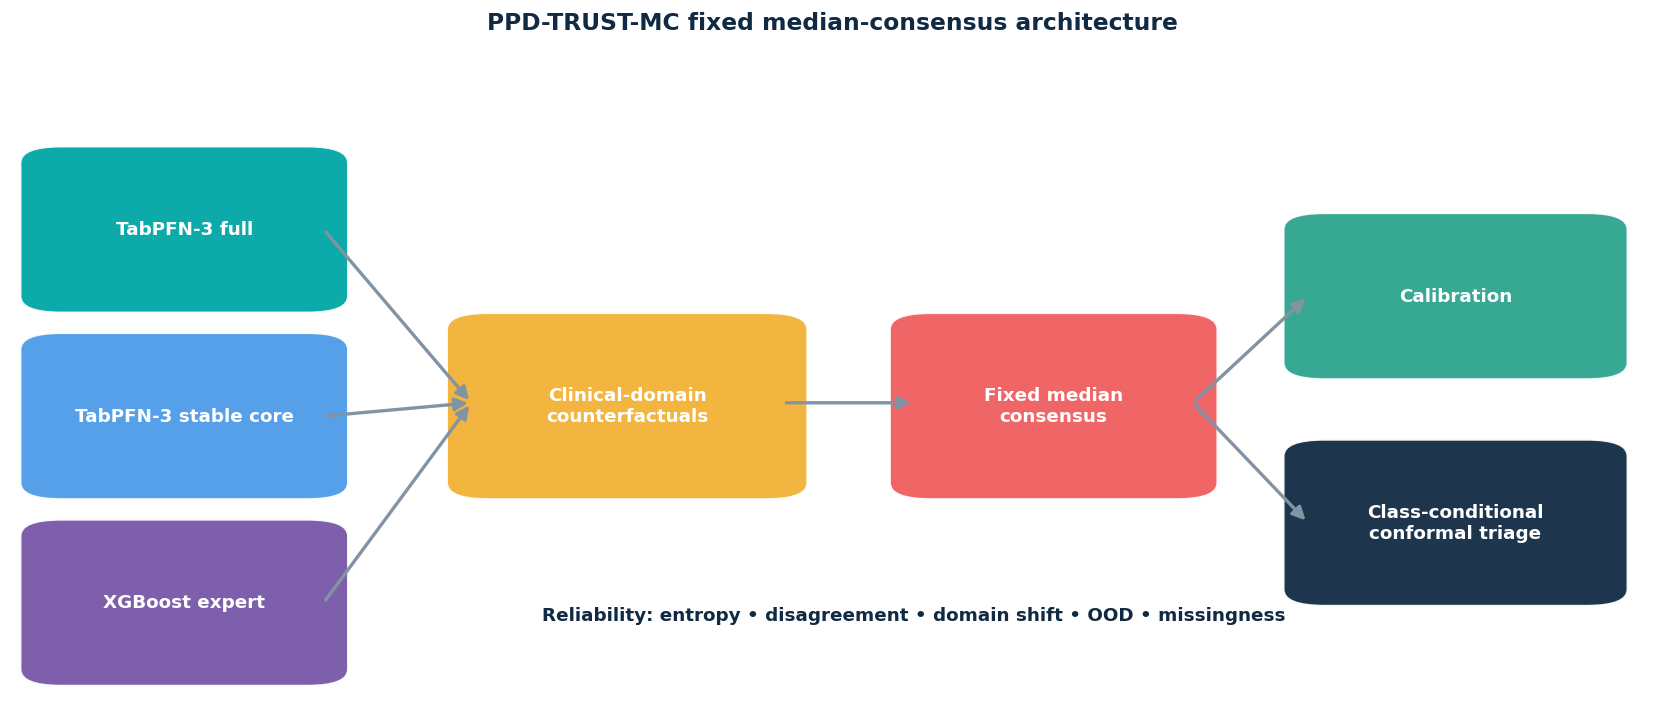

PPD-TRUST-MC fixed median-consensus model ready


In [ ]:
from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import NearestNeighbors
from sklearn.decomposition import TruncatedSVD
from sklearn.preprocessing import StandardScaler


def clip_probability(p):
    return np.clip(np.asarray(p, float), 1e-6, 1 - 1e-6)


def probability_logit(p):
    p = clip_probability(p)
    return np.log(p / (1 - p))


def binary_entropy(p):
    p = clip_probability(p)
    return -(p * np.log(p) + (1 - p) * np.log(1 - p)) / np.log(2)


def expected_calibration_error(y, p, bins=10):
    y = np.asarray(y).astype(int)
    p = clip_probability(p)
    order = np.argsort(p)
    parts = np.array_split(order, bins)
    return float(sum(len(idx) / len(y) * abs(y[idx].mean() - p[idx].mean()) for idx in parts if len(idx)))


def conformal_quantile(scores, alpha):
    scores = np.sort(np.asarray(scores, float))
    n = len(scores)
    if n == 0:
        return 1.0
    rank = int(np.ceil((n + 1) * (1 - alpha)))
    rank = min(max(rank, 1), n)
    return float(scores[rank - 1])


class SupportDistanceModel:
    def __init__(self, max_levels=12, components=24, neighbors=5, random_state=42):
        self.max_levels = max_levels
        self.components = components
        self.neighbors = neighbors
        self.random_state = random_state

    def fit(self, X):
        self.preprocessor_ = TabularPreprocessor(max_levels=self.max_levels).fit(X)
        Z = self.preprocessor_.transform(X)
        self.svd_ = None
        if Z.shape[1] > 30 and min(Z.shape) > 3:
            n_components = min(self.components, Z.shape[1] - 1, len(Z) - 1)
            if n_components >= 2:
                self.svd_ = TruncatedSVD(n_components=n_components, random_state=self.random_state)
                Z = self.svd_.fit_transform(Z)
        self.scaler_ = StandardScaler().fit(Z)
        Z = self.scaler_.transform(Z)
        k_train = min(self.neighbors + 1, len(Z))
        self.nn_ = NearestNeighbors(n_neighbors=k_train).fit(Z)
        distance = self.nn_.kneighbors(Z, return_distance=True)[0]
        reference = distance[:, 1:].mean(1) if distance.shape[1] > 1 else distance[:, 0]
        self.reference_median_ = float(np.median(reference))
        self.reference_iqr_ = float(np.subtract(*np.percentile(reference, [75, 25])) + 1e-9)
        return self

    def score(self, X):
        Z = self.preprocessor_.transform(X)
        if self.svd_ is not None:
            Z = self.svd_.transform(Z)
        Z = self.scaler_.transform(Z)
        k = min(self.neighbors, self.nn_.n_samples_fit_)
        distance = self.nn_.kneighbors(Z, n_neighbors=k, return_distance=True)[0].mean(1)
        return (distance - self.reference_median_) / self.reference_iqr_


class PPDTrustMC(ClassifierMixin, BaseEstimator):
    _estimator_type = 'classifier'

    def __init__(
        self,
        tabpfn_estimators=16,
        core_estimators=8,
        core_features=40,
        inner_folds=3,
        meta_folds=5,
        max_counterfactual_domains=5,
        alpha_negative=0.10,
        alpha_positive=0.05,
        minimum_triage_coverage=0.50,
        target_singleton_sensitivity=0.90,
        use_core=True,
        use_xgboost=True,
        use_logistic=False,
        use_counterfactual=True,
        use_reliability=True,
        random_state=42,
    ):
        self.tabpfn_estimators = tabpfn_estimators
        self.core_estimators = core_estimators
        self.core_features = core_features
        self.inner_folds = inner_folds
        self.meta_folds = meta_folds
        self.max_counterfactual_domains = max_counterfactual_domains
        self.alpha_negative = alpha_negative
        self.alpha_positive = alpha_positive
        self.minimum_triage_coverage = minimum_triage_coverage
        self.target_singleton_sensitivity = target_singleton_sensitivity
        self.use_core = use_core
        self.use_xgboost = use_xgboost
        self.use_logistic = use_logistic
        self.use_counterfactual = use_counterfactual
        self.use_reliability = use_reliability
        self.random_state = random_state

    def _expert_library(self, seed):
        experts = OrderedDict()
        experts['TabPFN-3-full'] = NativeTabPFNClassifier(
            n_estimators=self.tabpfn_estimators,
            random_state=seed,
        )
        if self.use_core:
            experts['TabPFN-3-stable-core'] = StableCoreTabPFNClassifier(
                k_features=self.core_features,
                n_estimators=self.core_estimators,
                random_state=seed + 101,
            )
        if self.use_xgboost:
            experts['XGBoost'] = make_xgboost(rs=seed + 211, calibrate=False)
        if self.use_logistic:
            experts['Logistic'] = make_logistic(rs=seed + 307, calibrate=False)
        return experts

    def _selected_domains(self, columns):
        domains = infer_clinical_domains(columns)
        ordered = sorted(domains.items(), key=lambda item: len(item[1]), reverse=True)
        return OrderedDict(ordered[:self.max_counterfactual_domains])

    def _counterfactual_details(self, full_model, X):
        frame = pd.DataFrame(X).copy()
        rows = []
        matrix = []
        base = full_model.predict_proba(frame)[:, 1]
        if not self.use_counterfactual:
            return np.zeros(len(frame)), base, pd.DataFrame(columns=['Domain','Mean absolute shift'])
        for domain, columns in self.domains_.items():
            selected = [c for c in columns if c in frame.columns]
            if hasattr(full_model, 'counterfactual_predict_proba'):
                probability = full_model.counterfactual_predict_proba(frame, selected)[:, 1]
            else:
                masked = frame.copy()
                for column in selected:
                    observed = masked[column].dropna()
                    if pd.to_numeric(masked[column], errors='coerce').notna().mean() >= .80:
                        replacement = pd.to_numeric(masked[column], errors='coerce').median()
                        replacement = float(replacement) if np.isfinite(replacement) else 0.0
                    else:
                        mode = observed.mode(dropna=True)
                        replacement = mode.iloc[0] if len(mode) else '__missing__'
                    masked[column] = replacement
                probability = full_model.predict_proba(masked)[:, 1]
            matrix.append(probability)
            rows.append({'Domain': domain, 'Mean absolute shift': float(np.mean(np.abs(probability-base)))})
        if not matrix:
            return np.zeros(len(frame)), base, pd.DataFrame(rows)
        matrix = np.column_stack(matrix)
        instability = np.max(np.abs(matrix - base[:, None]), axis=1)
        consensus = np.median(matrix, axis=1)
        return instability, consensus, pd.DataFrame(rows).sort_values('Mean absolute shift', ascending=False)

    @staticmethod
    def _performance_metrics(y, p):
        return {
            'AUROC': roc_auc_score(y, p),
            'AUPRC': average_precision_score(y, p),
            'Brier': brier_score_loss(y, p),
            'ECE': expected_calibration_error(y, p),
        }

    @staticmethod
    def _median_consensus(base_probability, counterfactual_consensus=None):
        matrix = np.asarray(base_probability, float)
        if counterfactual_consensus is not None:
            matrix = np.column_stack([matrix, counterfactual_consensus])
        return clip_probability(np.median(matrix, axis=1))

    @staticmethod
    def _uncertainty(probability, base_probability, missingness, support, instability):
        probability = clip_probability(probability)
        base_probability = np.asarray(base_probability, float)
        score = (
            .30 * binary_entropy(probability) +
            .25 * np.clip(base_probability.std(1) / .20, 0, 1) +
            .20 * np.clip(np.asarray(instability) / .20, 0, 1) +
            .15 * np.clip(np.maximum(np.asarray(support), 0) / 3.0, 0, 1) +
            .10 * np.asarray(missingness)
        )
        return np.clip(score, 0, 1)

    def _crossfit_calibration(self, y, probability):
        probability = clip_probability(probability)
        calibrated = np.zeros(len(y), float)
        splitter = StratifiedKFold(
            n_splits=min(self.meta_folds, int(np.bincount(y).min())),
            shuffle=True,
            random_state=self.random_state + 7001,
        )
        for train_idx, valid_idx in splitter.split(np.zeros(len(y)), y):
            model = LogisticRegression(C=1e4, max_iter=3000)
            model.fit(probability_logit(probability[train_idx]).reshape(-1, 1), y[train_idx])
            calibrated[valid_idx] = model.predict_proba(
                probability_logit(probability[valid_idx]).reshape(-1, 1)
            )[:, 1]
        final_model = LogisticRegression(C=1e4, max_iter=3000)
        final_model.fit(probability_logit(probability).reshape(-1, 1), y)
        accepted = (
            brier_score_loss(y, calibrated) < brier_score_loss(y, probability) and
            expected_calibration_error(y, calibrated) <= expected_calibration_error(y, probability) + .002 and
            average_precision_score(y, calibrated) >= average_precision_score(y, probability) - .001
        )
        return calibrated if accepted else probability, final_model if accepted else None, bool(accepted)

    @staticmethod
    def _optimal_threshold(y, probability):
        fpr, tpr, thresholds = roc_curve(y, probability)
        valid = np.isfinite(thresholds)
        return float(thresholds[valid][np.argmax((tpr-fpr)[valid])])

    def _select_reliability_cutoff(self, y, probability, uncertainty, q_negative, q_positive):
        include_negative = probability <= q_negative
        include_positive = (1-probability) <= q_positive
        conformal_singleton = include_negative ^ include_positive
        conformal_decision = include_positive.astype(int)
        if not self.use_reliability:
            return 1.0, {'Coverage': float(conformal_singleton.mean())}
        rows = []
        candidates = np.unique(np.quantile(uncertainty, np.linspace(.45, 1.0, 80)))
        for cutoff in candidates:
            accepted = conformal_singleton & (uncertainty <= cutoff)
            if accepted.mean() < self.minimum_triage_coverage or accepted.sum() < 30:
                continue
            if np.unique(y[accepted]).size < 2:
                continue
            tn, fp, fn, tp = confusion_matrix(y[accepted], conformal_decision[accepted], labels=[0,1]).ravel()
            sensitivity = tp / (tp+fn+1e-12)
            specificity = tn / (tn+fp+1e-12)
            rows.append({
                'Cutoff': float(cutoff),
                'Coverage': float(accepted.mean()),
                'Sensitivity': float(sensitivity),
                'Specificity': float(specificity),
                'Balanced accuracy': float(.5*(sensitivity+specificity)),
            })
        if not rows:
            return 1.0, {'Coverage': float(conformal_singleton.mean())}
        table = pd.DataFrame(rows)
        safe = table[table.Sensitivity >= self.target_singleton_sensitivity]
        candidates = safe if len(safe) else table
        selected = candidates.sort_values(
            ['Balanced accuracy','Sensitivity','Coverage'], ascending=[False,False,False]
        ).iloc[0]
        return float(selected.Cutoff), selected.to_dict()

    def fit(self, X, y):
        X = pd.DataFrame(X).reset_index(drop=True)
        y = np.asarray(y).astype(int)
        self.classes_ = np.array([0, 1])
        self.columns_ = list(X.columns)
        self.domains_ = self._selected_domains(self.columns_)
        splitter = StratifiedKFold(
            n_splits=min(self.inner_folds, int(np.bincount(y).min())),
            shuffle=True,
            random_state=self.random_state,
        )
        expert_names = None
        base_oof = None
        support_oof = np.zeros(len(y), float)
        instability_oof = np.zeros(len(y), float)
        cf_consensus_oof = np.zeros(len(y), float)
        missingness = X.isna().mean(axis=1).to_numpy(float)

        for fold, (train_idx, valid_idx) in enumerate(splitter.split(X, y)):
            X_train, X_valid = X.iloc[train_idx], X.iloc[valid_idx]
            y_train = y[train_idx]
            experts = self._expert_library(self.random_state + 100*fold)
            if expert_names is None:
                expert_names = list(experts)
                base_oof = np.zeros((len(y), len(expert_names)), float)
            fitted_experts = OrderedDict()
            for j, (name, estimator) in enumerate(experts.items()):
                fitted = clone(estimator).fit(X_train, y_train)
                fitted_experts[name] = fitted
                base_oof[valid_idx, j] = fitted.predict_proba(X_valid)[:, 1]
            support_model = SupportDistanceModel(random_state=self.random_state + fold).fit(X_train)
            support_oof[valid_idx] = support_model.score(X_valid)
            full_model = fitted_experts['TabPFN-3-full']
            instability_oof[valid_idx], cf_consensus_oof[valid_idx], _ = self._counterfactual_details(full_model, X_valid)
            del fitted_experts, experts, support_model
            gc.collect()

        self.expert_names_ = expert_names
        raw_oof = self._median_consensus(base_oof, cf_consensus_oof if self.use_counterfactual else None)
        calibrated_oof, self.calibrator_, self.calibration_accepted_ = self._crossfit_calibration(y, raw_oof)
        self.inner_raw_probability_ = raw_oof
        self.inner_probability_ = clip_probability(calibrated_oof)
        self.inner_metrics_ = self._performance_metrics(y, self.inner_probability_)
        self.threshold_ = self._optimal_threshold(y, self.inner_probability_)
        self.q_negative_ = conformal_quantile(self.inner_probability_[y == 0], self.alpha_negative)
        self.q_positive_ = conformal_quantile(1-self.inner_probability_[y == 1], self.alpha_positive)
        inner_uncertainty = self._uncertainty(
            self.inner_probability_, base_oof, missingness, support_oof, instability_oof
        )
        self.reliability_cutoff_, self.reliability_selection_ = self._select_reliability_cutoff(
            y, self.inner_probability_, inner_uncertainty, self.q_negative_, self.q_positive_
        )
        expert_rows = []
        for j, name in enumerate(self.expert_names_):
            expert_rows.append({'Expert': name, **self._performance_metrics(y, base_oof[:, j])})
        expert_rows.append({'Expert': 'Median consensus', **self._performance_metrics(y, self.inner_probability_)})
        self.expert_table_ = pd.DataFrame(expert_rows).sort_values('AUPRC', ascending=False)
        self.consensus_method_ = 'fixed-median-consensus'

        self.experts_ = OrderedDict()
        for name, estimator in self._expert_library(self.random_state + 9001).items():
            self.experts_[name] = clone(estimator).fit(X, y)
        self.support_model_ = SupportDistanceModel(random_state=self.random_state + 9101).fit(X)
        return self

    def _components(self, X):
        frame = pd.DataFrame(X).copy()
        frame.columns = self.columns_
        base = np.column_stack([
            estimator.predict_proba(frame)[:, 1]
            for estimator in self.experts_.values()
        ])
        missingness = frame.isna().mean(axis=1).to_numpy(float)
        support = self.support_model_.score(frame)
        instability, cf_consensus, domain_table = self._counterfactual_details(self.experts_['TabPFN-3-full'], frame)
        raw = self._median_consensus(base, cf_consensus if self.use_counterfactual else None)
        return frame, base, missingness, support, instability, cf_consensus, domain_table, raw

    def predict_proba(self, X):
        *_, raw = self._components(X)
        probability = raw
        if self.calibrator_ is not None:
            probability = self.calibrator_.predict_proba(probability_logit(raw).reshape(-1, 1))[:, 1]
        probability = clip_probability(probability)
        return np.column_stack([1-probability, probability])

    def predict(self, X):
        return (self.predict_proba(X)[:, 1] >= self.threshold_).astype(int)

    def predict_uncertainty(self, X):
        frame, base, missingness, support, instability, cf_consensus, domain_table, raw = self._components(X)
        probability = raw if self.calibrator_ is None else self.calibrator_.predict_proba(probability_logit(raw).reshape(-1,1))[:,1]
        return self._uncertainty(probability, base, missingness, support, instability)

    def predict_conformal(self, X):
        frame, base, missingness, support, instability, cf_consensus, domain_table, raw = self._components(X)
        probability = raw if self.calibrator_ is None else self.calibrator_.predict_proba(probability_logit(raw).reshape(-1,1))[:,1]
        probability = clip_probability(probability)
        uncertainty = self._uncertainty(probability, base, missingness, support, instability)
        include_negative = probability <= self.q_negative_
        include_positive = (1-probability) <= self.q_positive_
        singleton_negative = include_negative & ~include_positive
        singleton_positive = include_positive & ~include_negative
        conformal_referred = ~(singleton_negative | singleton_positive)
        reliability_referred = uncertainty > self.reliability_cutoff_
        referred = conformal_referred | reliability_referred
        decision = np.full(len(probability), -1, int)
        decision[singleton_negative & ~reliability_referred] = 0
        decision[singleton_positive & ~reliability_referred] = 1
        return {
            'probability': probability,
            'include_negative': include_negative,
            'include_positive': include_positive,
            'conformal_referred': conformal_referred,
            'reliability_referred': reliability_referred,
            'referred': referred,
            'decision': decision,
            'uncertainty': uncertainty,
        }

    def domain_sensitivity(self, X):
        _, _, _, _, _, _, table, _ = self._components(X)
        return table


def make_trust_mc(rs=RANDOM_STATE, **kwargs):
    parameters = {
        'tabpfn_estimators': TABPFN_ESTIMATORS,
        'core_estimators': TABPFN_CORE_ESTIMATORS,
        'core_features': CORE_K,
        'inner_folds': INNER_FOLDS,
        'meta_folds': META_FOLDS,
        'random_state': rs,
    }
    parameters.update(kwargs)
    return PPDTrustMC(**parameters)

fig, ax = plt.subplots(figsize=(14, 6.2))
ax.axis('off')
boxes = [
    (.02,.62,.17,.22,'TabPFN-3 full',TEAL),
    (.02,.34,.17,.22,'TabPFN-3 stable core',SKY),
    (.02,.06,.17,.22,'XGBoost expert',PURPLE),
    (.28,.34,.19,.25,'Clinical-domain\ncounterfactuals',GOLD),
    (.55,.34,.17,.25,'Fixed median\nconsensus',CORAL),
    (.79,.52,.18,.22,'Calibration',GREEN),
    (.79,.18,.18,.22,'Class-conditional\nconformal triage',NAVY),
]
for x,y0,w,h,label,color in boxes:
    ax.add_patch(FancyBboxPatch((x,y0),w,h,boxstyle='round,pad=.015,rounding_size=.025',
                                transform=ax.transAxes,facecolor=color,edgecolor='white',linewidth=1.5,alpha=.95))
    ax.text(x+w/2,y0+h/2,label,ha='center',va='center',color='white',weight='bold',fontsize=11,transform=ax.transAxes)
for a,b in [((.19,.73),(.28,.47)),((.19,.45),(.28,.47)),((.19,.17),(.28,.47)),((.47,.47),(.55,.47)),((.72,.47),(.79,.63)),((.72,.47),(.79,.29))]:
    ax.add_patch(FancyArrowPatch(a,b,transform=ax.transAxes,arrowstyle='-|>',mutation_scale=16,color=GREY,linewidth=2))
ax.text(.55,.15,'Reliability: entropy • disagreement • domain shift • OOD • missingness',
        ha='center',va='center',color=NAVY,weight='bold',fontsize=11,transform=ax.transAxes)
ax.set_title('PPD-TRUST-MC fixed median-consensus architecture', pad=12)
save_show(fig, 'stage06_architecture')

print('PPD-TRUST-MC fixed median-consensus model ready')

## Stage 7 — Repeated Nested Cross-Validation

TabPFN token loaded (length 53 )
INFO: You are downloading 'tabicl-classifier-v1-20250208.ckpt', the version used in our TabICLv1 paper.
A newer version, 'tabicl-classifier-v2-20260212.ckpt', is available and offers improved performance.

Checkpoint 'tabicl-classifier-v1-20250208.ckpt' not cached.



tabicl-classifier-v1-20250208.ckpt: reconstructing file:   0%|          |  0.00B /  108MB            

tabicl-classifier-v1-20250208.ckpt: downloading bytes:           |  0.00B            


Early stopping occurred at epoch 37 with best_epoch = 19 and best_valid_auc = 0.80028

Early stopping occurred at epoch 30 with best_epoch = 12 and best_valid_auc = 0.68182

Early stopping occurred at epoch 40 with best_epoch = 22 and best_valid_auc = 0.80923
repeat 1/5 fold 1/5

Early stopping occurred at epoch 41 with best_epoch = 23 and best_valid_auc = 0.84435

Early stopping occurred at epoch 29 with best_epoch = 11 and best_valid_auc = 0.85882
Stop training because you reached max_epochs = 60 with best_epoch = 53 and best_valid_auc = 0.88774
repeat 1/5 fold 2/5

Early stopping occurred at epoch 47 with best_epoch = 29 and best_valid_auc = 0.83058

Early stopping occurred at epoch 41 with best_epoch = 23 and best_valid_auc = 0.70937

Early stopping occurred at epoch 27 with best_epoch = 9 and best_valid_auc = 0.80372
repeat 1/5 fold 3/5

Early stopping occurred at epoch 42 with best_epoch = 24 and best_valid_auc = 0.85675
Stop training because you reached max_epochs = 60 with bes

,repeat,fold,consensus,calibration,threshold,q_negative,q_positive,reliability_cutoff,AUROC,AUPRC,Brier,ECE
0,1,1,fixed-median-consensus,False,0.5861,0.7507,0.7553,0.5277,0.8339,0.8685,0.1646,0.0269
1,1,2,fixed-median-consensus,False,0.6558,0.7738,0.7333,0.5109,0.8274,0.8539,0.1672,0.0522
2,1,3,fixed-median-consensus,False,0.5882,0.7372,0.7566,0.5445,0.8099,0.8421,0.1759,0.0484
3,1,4,fixed-median-consensus,False,0.6872,0.7378,0.7643,0.5386,0.8240,0.8656,0.1693,0.0313
4,1,5,fixed-median-consensus,False,0.6963,0.7528,0.7393,0.5457,0.8335,0.8560,0.1626,0.0540
5,2,1,fixed-median-consensus,False,0.7015,0.7558,0.7344,0.5217,0.8134,0.8494,0.1739,0.0518
6,2,2,fixed-median-consensus,False,0.5461,0.7685,0.7220,0.5121,0.8338,0.8687,0.1637,0.0253
7,2,3,fixed-median-consensus,False,0.6018,0.7671,0.7425,0.6780,0.8063,0.8450,0.1776,0.0374
8,2,4,fixed-median-consensus,False,0.5841,0.7681,0.7610,0.7050,0.8269,0.8603,0.1672,0.0167
9,2,5,fixed-median-consensus,False,0.5923,0.7617,0.7530,0.5925,0.8311,0.8686,0.1653,0.0231


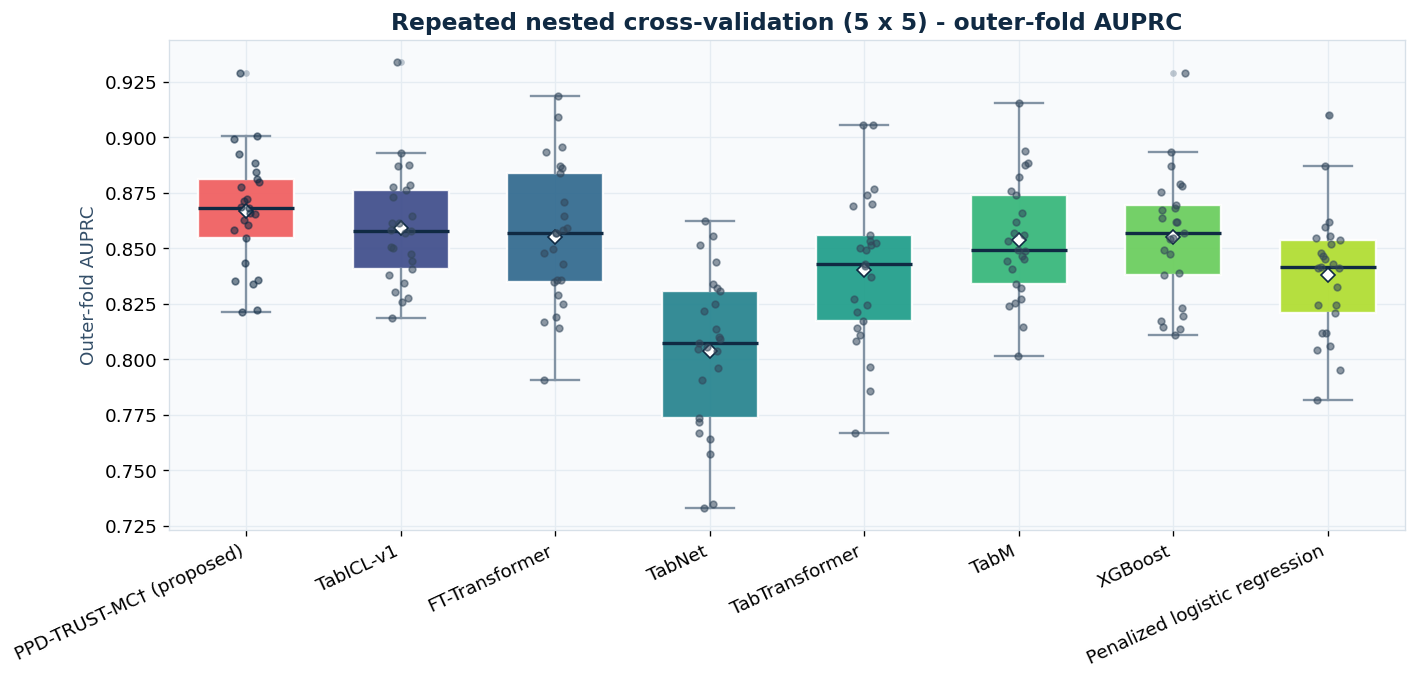

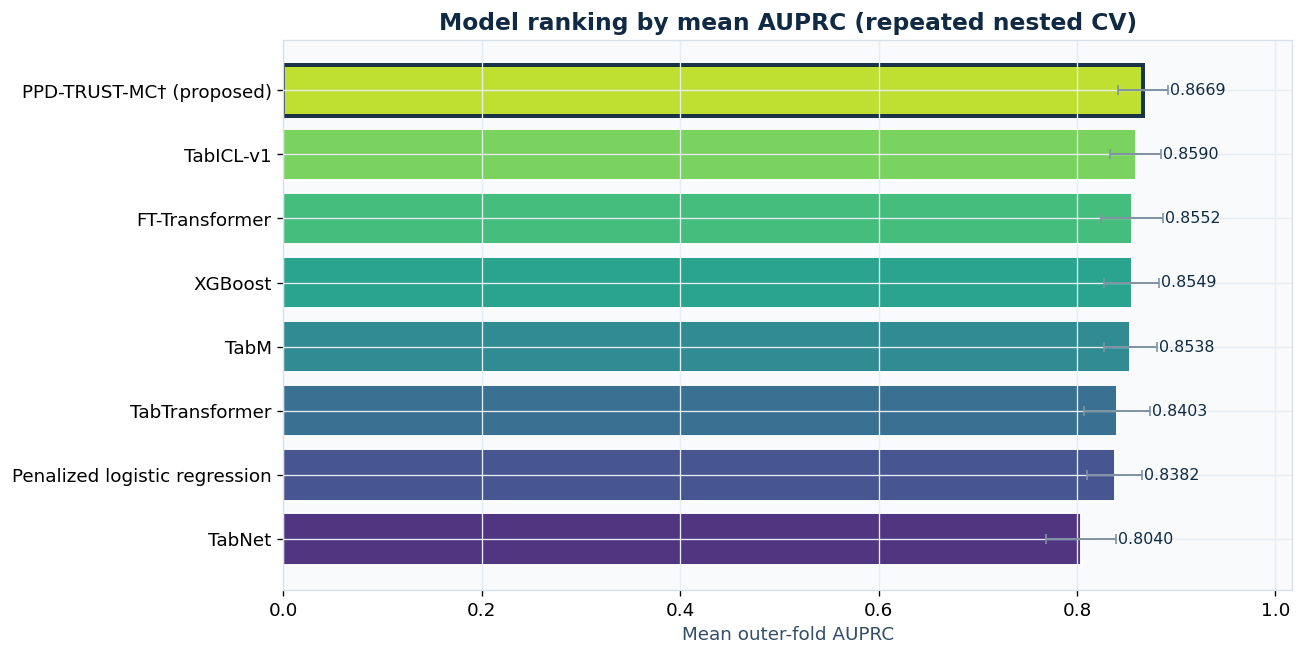

In [ ]:
import os, gc, pickle, hashlib
from pathlib import Path
from collections import OrderedDict
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.base import clone
from sklearn.model_selection import StratifiedKFold
from sklearn.metrics import roc_auc_score, average_precision_score, brier_score_loss


def cv_signature(Xd, yv, estimators, repeats, folds, seed):
    params = [(name, repr(est.get_params(deep=True))) for name, est in estimators.items()]
    payload = ('tabpfn3-fixed-median-tabm-corrected-v4', len(yv), int(np.sum(yv)), tuple(map(str, Xd.columns)), repeats, folds, seed, params)
    return hashlib.sha256(repr(payload).encode('utf-8')).hexdigest()


def run_nested_cv(Xd, yv, estimators, repeats=OUTER_REPEATS, folds=OUTER_FOLDS,
                  seed=RANDOM_STATE, checkpoint_path=None):
    n = len(yv)
    names = list(estimators)
    signature = cv_signature(Xd, yv, estimators, repeats, folds, seed)
    state = {
        'signature': signature,
        'oof_sum': {name: np.zeros(n, float) for name in names},
        'oof_count': {name: np.zeros(n, float) for name in names},
        'fold_metrics': {name: [] for name in names},
        'diagnostics': {name: [] for name in names},
        'triage': [],
        'done': set(),
        'errors': {},
    }
    cp = Path(checkpoint_path) if checkpoint_path else None
    if cp is not None and cp.exists():
        with open(cp, 'rb') as handle:
            loaded = pickle.load(handle)
        if loaded.get('signature') == signature:
            state = loaded
            print('Resumed jobs:', len(state['done']))

    for repeat in range(repeats):
        splitter = StratifiedKFold(folds, shuffle=True, random_state=seed + repeat)
        for fold, (train_idx, test_idx) in enumerate(splitter.split(Xd, yv), 1):
            for name, estimator in estimators.items():
                job = (repeat, fold, name)
                if job in state['done']:
                    continue
                try:
                    fitted = clone(estimator).fit(Xd.iloc[train_idx], yv[train_idx])
                    probability = fitted.predict_proba(Xd.iloc[test_idx])[:, 1]
                    state['oof_sum'][name][test_idx] += probability
                    state['oof_count'][name][test_idx] += 1
                    state['fold_metrics'][name].append({
                        'repeat': repeat + 1,
                        'fold': fold,
                        'AUROC': roc_auc_score(yv[test_idx], probability),
                        'AUPRC': average_precision_score(yv[test_idx], probability),
                        'Brier': brier_score_loss(yv[test_idx], probability),
                    })
                    if name == PRIMARY:
                        triage = fitted.predict_conformal(Xd.iloc[test_idx])
                        for local, original_index in enumerate(test_idx):
                            state['triage'].append({
                                'repeat': repeat + 1,
                                'fold': fold,
                                'index': int(original_index),
                                'y': int(yv[original_index]),
                                'probability': float(triage['probability'][local]),
                                'include_negative': bool(triage['include_negative'][local]),
                                'include_positive': bool(triage['include_positive'][local]),
                                'conformal_referred': bool(triage['conformal_referred'][local]),
                                'reliability_referred': bool(triage['reliability_referred'][local]),
                                'referred': bool(triage['referred'][local]),
                                'decision': int(triage['decision'][local]),
                                'uncertainty': float(triage['uncertainty'][local]),
                            })
                        state['diagnostics'][name].append({
                            'repeat': repeat + 1,
                            'fold': fold,
                            'consensus': fitted.consensus_method_,
                            'calibration': fitted.calibration_accepted_,
                            'threshold': fitted.threshold_,
                            'q_negative': fitted.q_negative_,
                            'q_positive': fitted.q_positive_,
                            'reliability_cutoff': fitted.reliability_cutoff_,
                            **fitted.inner_metrics_,
                        })
                    del fitted
                    gc.collect()
                except Exception as error:
                    state['errors'][job] = repr(error)
                    print('FAILED', job, repr(error))
                    if name == PRIMARY:
                        raise
                state['done'].add(job)
                if cp is not None:
                    cp.parent.mkdir(parents=True, exist_ok=True)
                    with open(cp, 'wb') as handle:
                        pickle.dump(state, handle, pickle.HIGHEST_PROTOCOL)
            print(f'repeat {repeat + 1}/{repeats} fold {fold}/{folds}')

    valid_names = [name for name in names if np.all(state['oof_count'][name] > 0)]
    oof = {name: state['oof_sum'][name] / state['oof_count'][name] for name in valid_names}
    fold_metrics = {name: pd.DataFrame(state['fold_metrics'][name]) for name in valid_names}
    diagnostics = {name: pd.DataFrame(state['diagnostics'][name]) for name in valid_names}
    triage = pd.DataFrame(state['triage'])
    return oof, fold_metrics, diagnostics, triage, state['errors']


# --- TabPFN token: recover from env / variable / Colab Secrets / client cache ---
def _ensure_tabpfn_token():
    token = str(os.environ.get('TABPFN_TOKEN', '') or '').strip()
    if not token:
        token = str(globals().get('TABPFN_TOKEN', '') or '').strip()
    if not token:
        try:
            from google.colab import userdata
            token = str(userdata.get('TABPFN_TOKEN') or '').strip()
        except Exception:
            pass
    if not token:
        try:
            import tabpfn_client
            token = str(tabpfn_client.get_access_token() or '').strip()
        except Exception:
            pass
    if not token:
        raise RuntimeError(
            'TABPFN_TOKEN not found (env, variable, Colab Secrets, or tabpfn_client cache). '
            'The runtime was probably restarted - re-run the authentication stage.'
        )
    os.environ['TABPFN_TOKEN'] = token
    try:
        import tabpfn_client
        tabpfn_client.set_access_token(token)
    except Exception:
        pass
    print('TabPFN token loaded (length', len(token), ')')

_ensure_tabpfn_token()


MODELS = OrderedDict()
MODELS[PRIMARY] = make_trust_mc()
MODELS[TABICL_BASELINE] = make_standard_tabicl(n_estimators=TABICL_ESTIMATORS, calibrate=True)
if RUN_DEEP_BASELINES:
    MODELS['FT-Transformer'] = make_ft(calibrate=True)
    MODELS['TabNet'] = make_tabnet(calibrate=True)
    MODELS['TabTransformer'] = make_tabtransformer(calibrate=True)
    MODELS['TabM'] = make_tabm(calibrate=True)
MODELS['XGBoost'] = make_xgboost(calibrate=True)
MODELS['Penalized logistic regression'] = make_logistic(calibrate=True)

OOF, FOLD_METRICS, MODEL_DIAGNOSTICS, TRIAGE_RECORDS, CV_ERRORS = run_nested_cv(
    Xm, y, MODELS,
    checkpoint_path=RESULT_DIR / 'ppd_trust_mc_tabpfn3_fixed_median_authenticated_nested_cv.pkl'
)

if PRIMARY not in OOF:
    raise RuntimeError(CV_ERRORS)

display(styled_table(MODEL_DIAGNOSTICS.get(PRIMARY, pd.DataFrame()), 'AUPRC', 4))

fold_long = pd.concat([
    frame.assign(Model=name) for name, frame in FOLD_METRICS.items() if len(frame)
], ignore_index=True)

labels = list(FOLD_METRICS)
auprc_data = [FOLD_METRICS[name].AUPRC.values for name in labels]

# --- Repeated nested cross-validation: boxplot of outer-fold AUPRC -----------
fig, ax = plt.subplots(figsize=(12, 5.8))
box = ax.boxplot(
    auprc_data, patch_artist=True, widths=.62, showmeans=True,
    medianprops=dict(color=NAVY, linewidth=2),
    meanprops=dict(marker='D', markerfacecolor='white', markeredgecolor=NAVY, markersize=6),
    whiskerprops=dict(color=GREY, linewidth=1.4),
    capprops=dict(color=GREY, linewidth=1.4),
    flierprops=dict(marker='o', markersize=4, markerfacecolor=GREY, markeredgecolor='none', alpha=.5),
)
box_colors = plt.cm.viridis(np.linspace(.12, .88, len(labels)))
for patch, name, color in zip(box['boxes'], labels, box_colors):
    patch.set_facecolor(CORAL if name == PRIMARY else color)
    patch.set_edgecolor('white'); patch.set_alpha(.92); patch.set_linewidth(1.4)
for local, name in enumerate(labels, start=1):
    values = FOLD_METRICS[name].AUPRC.values
    jitter = (np.random.default_rng(RANDOM_STATE + local).random(len(values)) - .5) * .16
    ax.scatter(np.full(len(values), local) + jitter, values, s=16,
               color=NAVY if name == PRIMARY else '#33475B', alpha=.55, zorder=3)
ax.set_xticks(np.arange(1, len(labels) + 1), labels, rotation=25, ha='right')
ax.set(ylabel='Outer-fold AUPRC',
       title=f'Repeated nested cross-validation ({OUTER_REPEATS} x {OUTER_FOLDS}) - outer-fold AUPRC')
save_show(fig, 'stage07_nested_cv_auprc_boxplot')

# --- Separate AUPRC ranking figure (viridis) --------------------------------
ranking = (
    pd.DataFrame({
        'Model': labels,
        'AUPRC': [float(np.mean(v)) for v in auprc_data],
        'SD': [float(np.std(v)) for v in auprc_data],
    })
    .sort_values('AUPRC', ascending=True)
    .reset_index(drop=True)
)
fig, ax = plt.subplots(figsize=(11, 5.6))
rank_colors = plt.cm.viridis(np.linspace(.12, .9, len(ranking)))
bars = ax.barh(ranking.Model, ranking.AUPRC, xerr=ranking.SD, color=rank_colors,
               edgecolor='white', linewidth=1.2, alpha=.95,
               error_kw=dict(ecolor=GREY, elinewidth=1.2, capsize=3))
for bar, name in zip(bars, ranking.Model):
    if name == PRIMARY:
        bar.set_edgecolor(NAVY); bar.set_linewidth(2.4)
for row, value in enumerate(ranking.AUPRC):
    ax.text(value + ranking.SD.iloc[row] + .002, row, f'{value:.4f}',
            va='center', fontsize=9.5, color=NAVY)
ax.set(xlabel='Mean outer-fold AUPRC',
       title='Model ranking by mean AUPRC (repeated nested CV)')
ax.margins(x=.14)
save_show(fig, 'stage07_auprc_ranking_viridis')

## Stage 8 — Primary Discrimination

,Rank,Model,AUROC,AUROC 95% CI,AUPRC,AUPRC 95% CI
0,1,PPD-TRUST-MC† (proposed),0.8283,"[0.801, 0.855]",0.8644,"[0.839, 0.889]"
1,2,FT-Transformer,0.8241,"[0.794, 0.851]",0.8557,"[0.827, 0.884]"
2,3,TabICL-v1,0.8247,"[0.795, 0.853]",0.8554,"[0.828, 0.883]"
3,4,TabM,0.8218,"[0.793, 0.850]",0.8549,"[0.827, 0.881]"
4,5,XGBoost,0.8179,"[0.788, 0.846]",0.8533,"[0.826, 0.881]"
5,6,TabTransformer,0.8174,"[0.788, 0.846]",0.8466,"[0.816, 0.875]"
6,7,Penalized logistic regression,0.8071,"[0.778, 0.836]",0.8391,"[0.811, 0.867]"
7,8,TabNet,0.8024,"[0.771, 0.833]",0.8386,"[0.809, 0.867]"


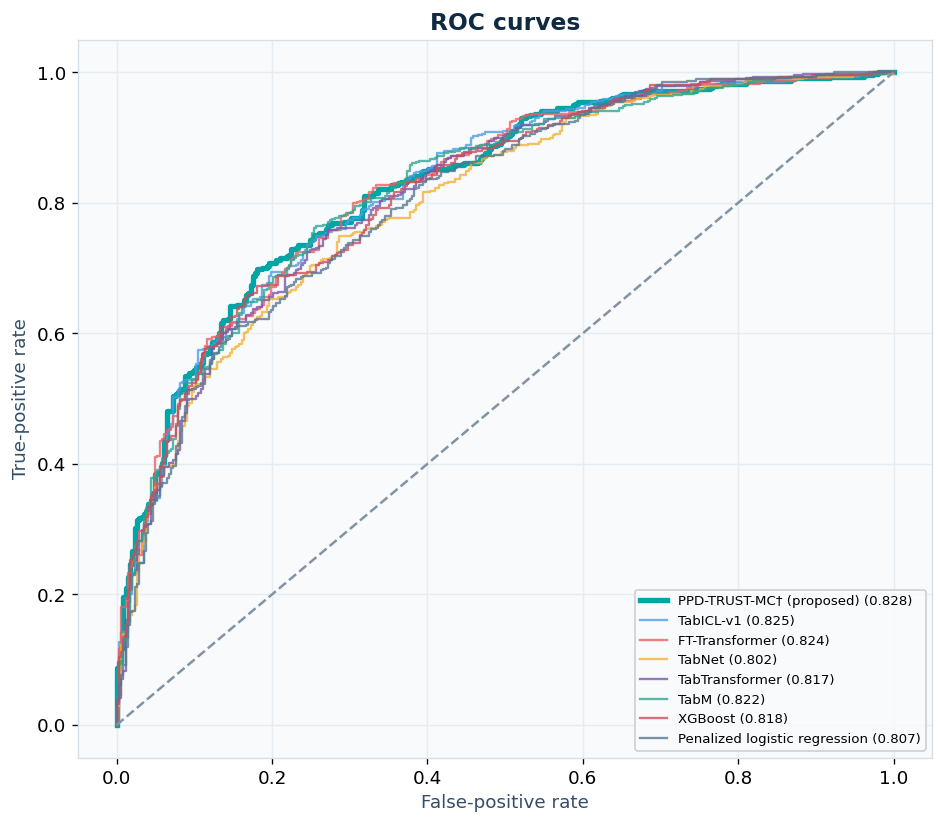

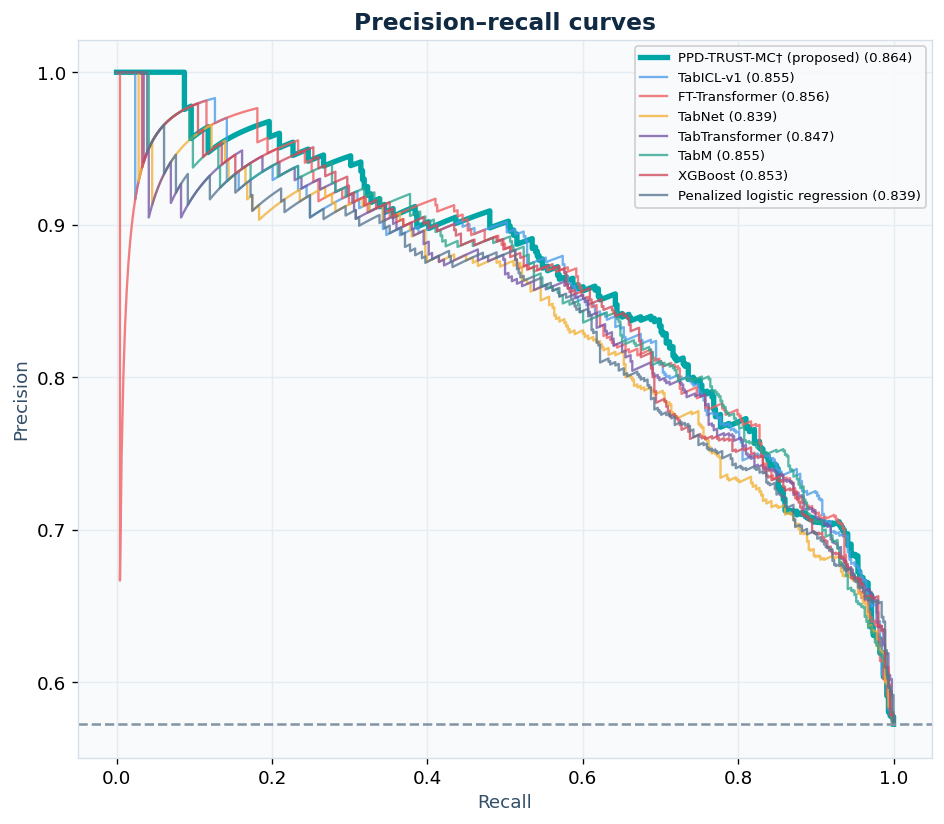

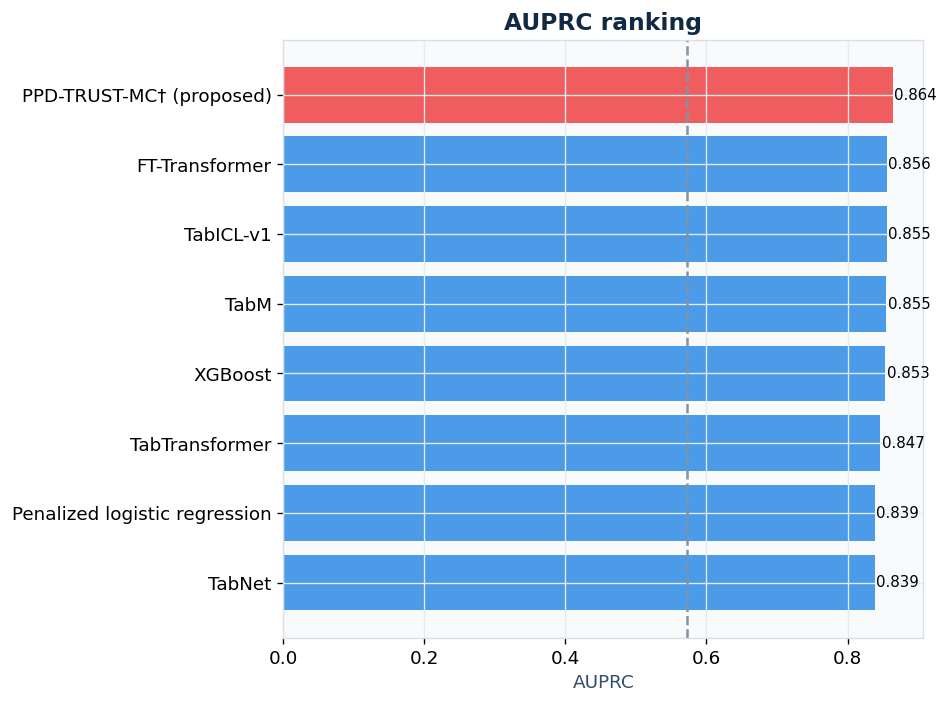

In [ ]:
def stratified_bootstrap_indices(y_true, rng):
    y_true = np.asarray(y_true)
    negative = np.flatnonzero(y_true == 0)
    positive = np.flatnonzero(y_true == 1)
    index = np.concatenate([
        rng.choice(negative, len(negative), replace=True),
        rng.choice(positive, len(positive), replace=True),
    ])
    rng.shuffle(index)
    return index


def bootstrap_metric(y_true, probability, function, B=N_BOOT, seed=RANDOM_STATE + 100):
    rng_local = np.random.default_rng(seed)
    values = []
    for _ in range(B):
        index = stratified_bootstrap_indices(y_true, rng_local)
        values.append(function(y_true[index], probability[index]))
    return float(function(y_true, probability)), np.quantile(values, [.025, .975]), np.asarray(values)

rows = []
BOOTSTRAPS = {}
for order, (name, probability) in enumerate(OOF.items()):
    auroc, auroc_ci, auroc_boot = bootstrap_metric(y, probability, roc_auc_score, seed=RANDOM_STATE + order)
    auprc, auprc_ci, auprc_boot = bootstrap_metric(y, probability, average_precision_score, seed=RANDOM_STATE + 1000 + order)
    rows.append({
        'Model': name,
        'AUROC': auroc,
        'AUROC low': auroc_ci[0],
        'AUROC high': auroc_ci[1],
        'AUROC 95% CI': f'[{auroc_ci[0]:.3f}, {auroc_ci[1]:.3f}]',
        'AUPRC': auprc,
        'AUPRC low': auprc_ci[0],
        'AUPRC high': auprc_ci[1],
        'AUPRC 95% CI': f'[{auprc_ci[0]:.3f}, {auprc_ci[1]:.3f}]',
    })
    BOOTSTRAPS[name] = {'AUROC': auroc_boot, 'AUPRC': auprc_boot}

discrimination = pd.DataFrame(rows).sort_values(['AUPRC', 'AUROC'], ascending=False).reset_index(drop=True)
discrimination.insert(0, 'Rank', np.arange(1, len(discrimination) + 1))
display(styled_table(discrimination[['Rank','Model','AUROC','AUROC 95% CI','AUPRC','AUPRC 95% CI']], 'AUPRC', 4))

# ---------- Figure 1: ROC curves ----------
fig1, ax1 = plt.subplots(figsize=(8, 7))
for idx, (name, probability) in enumerate(OOF.items()):
    fpr, tpr, _ = roc_curve(y, probability)
    width = 3.2 if name == PRIMARY else 1.4
    alpha = 1 if name == PRIMARY else .78
    color = PALETTE[idx % len(PALETTE)]
    ax1.plot(fpr, tpr, lw=width, alpha=alpha, color=color,
             label=f'{name} ({roc_auc_score(y, probability):.3f})')
ax1.plot([0, 1], [0, 1], '--', color=GREY)
ax1.set(xlabel='False-positive rate', ylabel='True-positive rate', title='ROC curves')
ax1.legend(fontsize=8)
save_show(fig1, 'stage08_roc_curves')

# ---------- Figure 2: Precision–recall curves ----------
fig2, ax2 = plt.subplots(figsize=(8, 7))
for idx, (name, probability) in enumerate(OOF.items()):
    precision, recall, _ = precision_recall_curve(y, probability)
    width = 3.2 if name == PRIMARY else 1.4
    alpha = 1 if name == PRIMARY else .78
    color = PALETTE[idx % len(PALETTE)]
    ax2.plot(recall, precision, lw=width, alpha=alpha, color=color,
             label=f'{name} ({average_precision_score(y, probability):.3f})')
ax2.axhline(y.mean(), ls='--', color=GREY)
ax2.set(xlabel='Recall', ylabel='Precision', title='Precision–recall curves')
ax2.legend(fontsize=8)
save_show(fig2, 'stage08_pr_curves')

# ---------- Figure 3: AUPRC ranking ----------
fig3, ax3 = plt.subplots(figsize=(8, 6))
ranked = discrimination.sort_values('AUPRC')
colors = [CORAL if name == PRIMARY else SKY for name in ranked.Model]
ax3.barh(ranked.Model, ranked.AUPRC, color=colors)
ax3.axvline(y.mean(), ls='--', color=GREY)
ax3.set(xlabel='AUPRC', title='AUPRC ranking')
for patch, value in zip(ax3.patches, ranked.AUPRC):
    ax3.text(value + .002, patch.get_y() + patch.get_height() / 2,
             f'{value:.3f}', va='center', fontsize=9)
save_show(fig3, 'stage08_auprc_ranking')

## Stage 9 — Threshold Performance

,Model,Balanced accuracy,MCC,Sensitivity,Specificity,Precision,NPV,Median threshold
0,PPD-TRUST-MC† (proposed),0.7529,0.5007,0.6987,0.8070,0.8290,0.6667,0.6208
5,TabM,0.7461,0.4899,0.7642,0.7281,0.7901,0.6975,0.5376
2,FT-Transformer,0.7377,0.4773,0.7882,0.6871,0.7714,0.7078,0.5068
1,TabICL-v1,0.7375,0.4703,0.6856,0.7895,0.8135,0.6522,0.6035
6,XGBoost,0.7361,0.4690,0.6594,0.8129,0.8251,0.6406,0.6465
4,TabTransformer,0.7302,0.4557,0.7118,0.7485,0.7913,0.6598,0.5368
3,TabNet,0.7188,0.4339,0.7183,0.7193,0.7741,0.6560,0.5642
7,Penalized logistic regression,0.7183,0.4351,0.6266,0.8099,0.8153,0.6183,0.6221


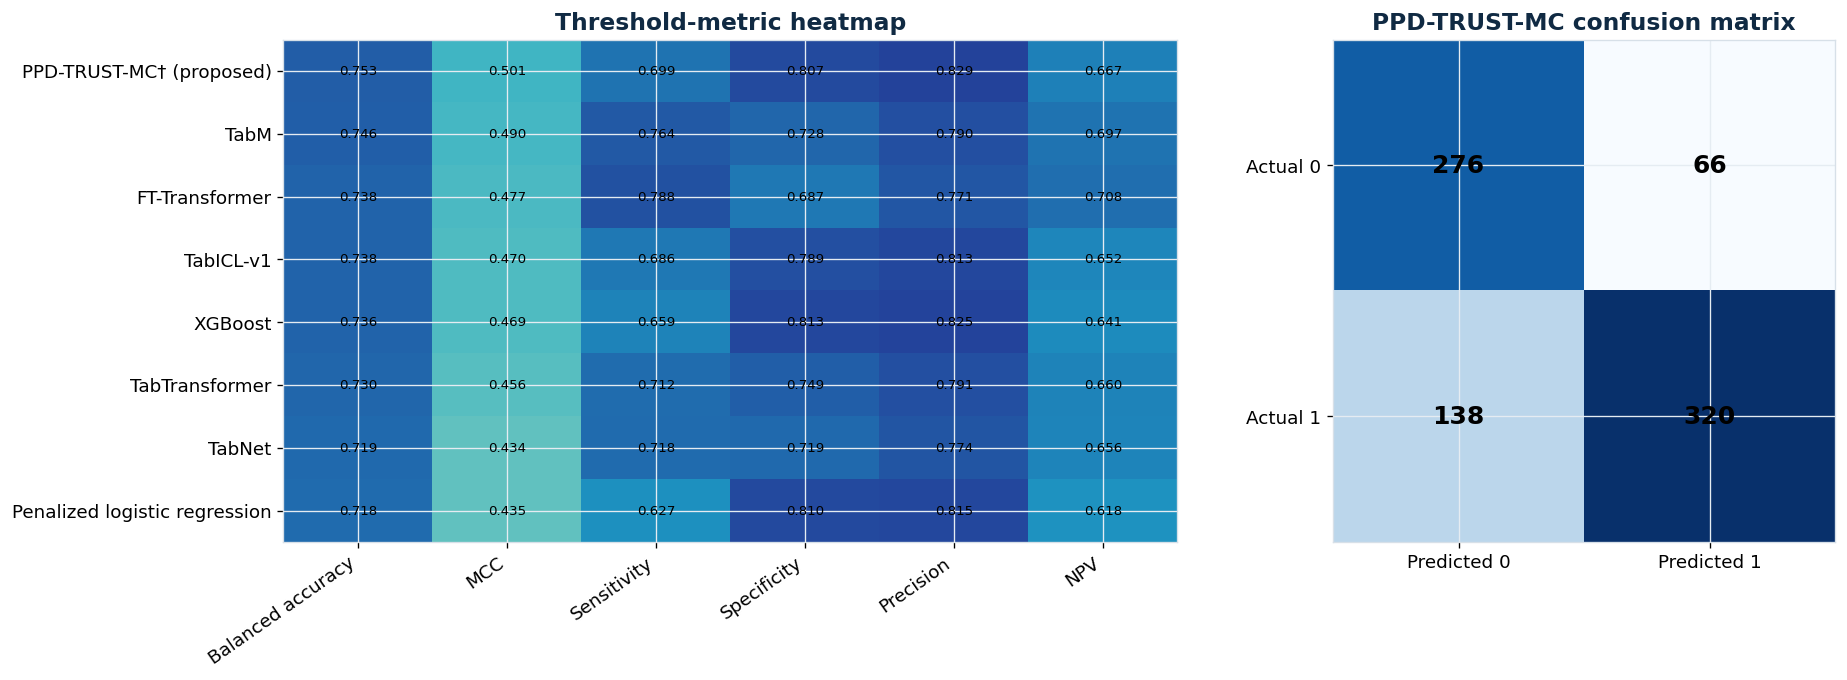

In [ ]:
def optimal_threshold(y_true, probability):
    thresholds = np.unique(np.quantile(probability, np.linspace(0.01, .99, 199)))
    best = None
    for threshold in thresholds:
        predicted = (probability >= threshold).astype(int)
        tn, fp, fn, tp = confusion_matrix(y_true, predicted, labels=[0, 1]).ravel()
        sensitivity = tp / (tp + fn + 1e-12)
        specificity = tn / (tn + fp + 1e-12)
        balacc = .5 * (sensitivity + specificity)
        score = (balacc, sensitivity, specificity)
        if best is None or score > best[0]:
            best = (score, float(threshold))
    return best[1]


def cross_fitted_threshold_predictions(y_true, probability, folds=5, seed=42):
    predicted = np.zeros(len(y_true), int)
    thresholds = []
    splitter = StratifiedKFold(folds, shuffle=True, random_state=seed)
    for train_idx, test_idx in splitter.split(np.zeros(len(y_true)), y_true):
        threshold = optimal_threshold(y_true[train_idx], probability[train_idx])
        predicted[test_idx] = (probability[test_idx] >= threshold).astype(int)
        thresholds.append(threshold)
    return predicted, np.asarray(thresholds)


def threshold_metrics(y_true, predicted):
    tn, fp, fn, tp = confusion_matrix(y_true, predicted, labels=[0, 1]).ravel()
    return {
        'Balanced accuracy': balanced_accuracy_score(y_true, predicted),
        'MCC': matthews_corrcoef(y_true, predicted),
        'Sensitivity': tp / (tp + fn + 1e-12),
        'Specificity': tn / (tn + fp + 1e-12),
        'Precision': tp / (tp + fp + 1e-12),
        'NPV': tn / (tn + fn + 1e-12),
    }

THRESHOLD_PREDICTIONS = {}
THRESHOLDS = {}
threshold_rows = []
for name, probability in OOF.items():
    prediction, thresholds = cross_fitted_threshold_predictions(y, probability, OUTER_FOLDS, RANDOM_STATE)
    THRESHOLD_PREDICTIONS[name] = prediction
    THRESHOLDS[name] = thresholds
    threshold_rows.append({'Model': name, **threshold_metrics(y, prediction), 'Median threshold': np.median(thresholds)})
threshold_results = pd.DataFrame(threshold_rows).sort_values('Balanced accuracy', ascending=False)
display(styled_table(threshold_results, 'Balanced accuracy', 4))

metrics = ['Balanced accuracy','MCC','Sensitivity','Specificity','Precision','NPV']
heat = threshold_results.set_index('Model')[metrics]
fig, axes = plt.subplots(1, 2, figsize=(16, 5.8), gridspec_kw={'width_ratios':[1.45,1]})
im = axes[0].imshow(heat.values, aspect='auto', cmap='YlGnBu', vmin=0, vmax=1)
axes[0].set_xticks(range(len(metrics)), metrics, rotation=35, ha='right')
axes[0].set_yticks(range(len(heat)), heat.index)
for i in range(heat.shape[0]):
    for j in range(heat.shape[1]):
        axes[0].text(j, i, f'{heat.iloc[i,j]:.3f}', ha='center', va='center', fontsize=8)
axes[0].set_title('Threshold-metric heatmap')
cm = confusion_matrix(y, THRESHOLD_PREDICTIONS[PRIMARY], labels=[0,1])
axes[1].imshow(cm, cmap='Blues')
axes[1].set_xticks([0,1], ['Predicted 0','Predicted 1'])
axes[1].set_yticks([0,1], ['Actual 0','Actual 1'])
for i in range(2):
    for j in range(2):
        axes[1].text(j,i,f'{cm[i,j]:,}',ha='center',va='center',fontsize=15,weight='bold')
axes[1].set_title('PPD-TRUST-MC confusion matrix')
save_show(fig, 'stage09_threshold_performance')

## Stage 10 — Calibration

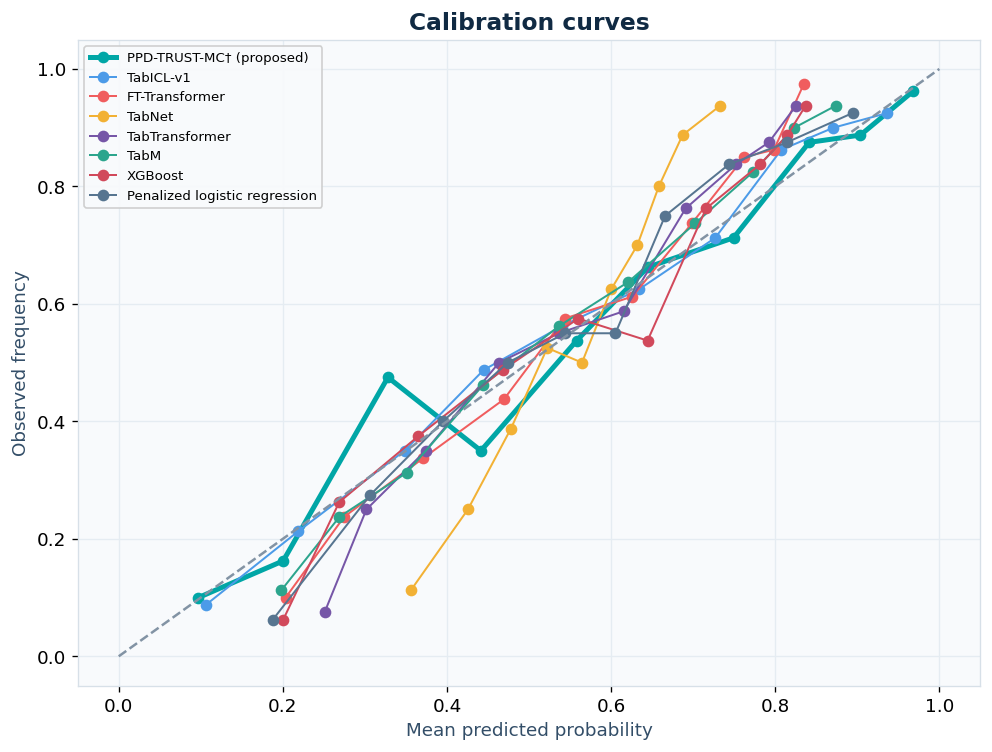

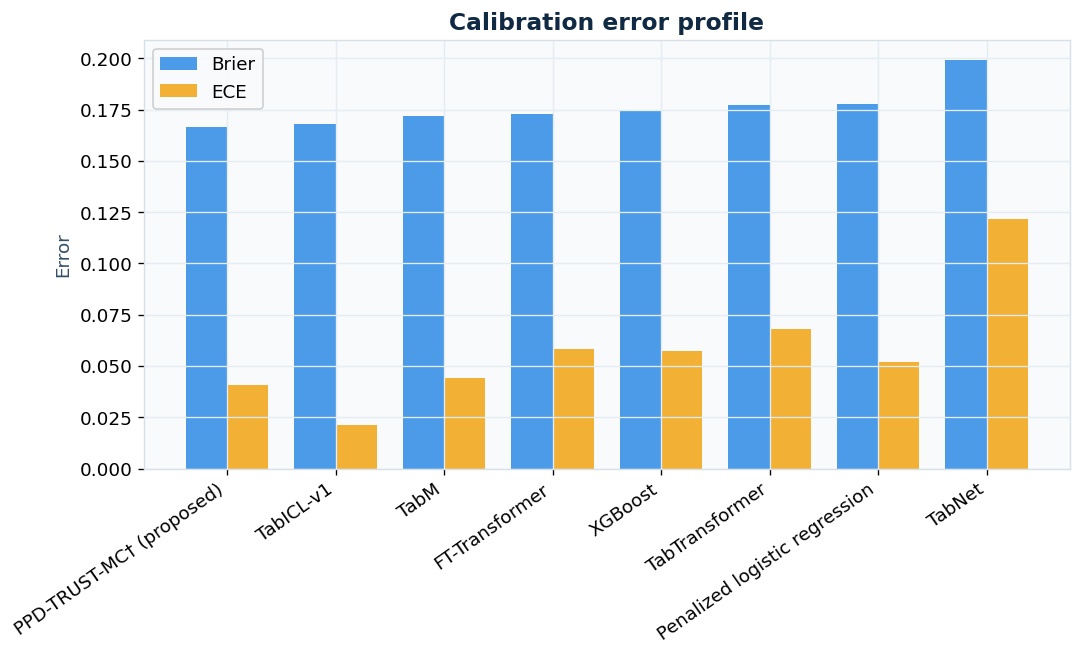

,Model,Brier,ECE,Intercept,Slope
0,PPD-TRUST-MC† (proposed),0.1665,0.0410,0.0044,0.9517
1,TabICL-v1,0.1679,0.0210,0.0424,1.0594
5,TabM,0.1719,0.0443,0.0182,1.3344
2,FT-Transformer,0.1729,0.0582,-0.0111,1.4550
6,XGBoost,0.1747,0.0572,-0.0396,1.3400
4,TabTransformer,0.1773,0.0682,-0.0324,1.5375
7,Penalized logistic regression,0.1780,0.0519,-0.0160,1.3653
3,TabNet,0.1992,0.1216,-0.3819,2.6885


In [ ]:
def calibration_intercept_slope(y_true, probability):
    z = probability_logit(probability)
    def objective(theta):
        q = 1 / (1 + np.exp(-np.clip(theta[0] + theta[1] * z, -30, 30)))
        return -np.mean(y_true * np.log(q + 1e-12) + (1 - y_true) * np.log(1 - q + 1e-12))
    result = minimize(objective, np.array([0.0, 1.0]), method='BFGS')
    return float(result.x[0]), float(result.x[1])

calibration_rows = []

# --- Calibration curves (separate figure) -----------------------------------
fig, ax = plt.subplots(figsize=(8.4, 6.4))
for idx, (name, probability) in enumerate(OOF.items()):
    intercept, slope = calibration_intercept_slope(y, probability)
    calibration_rows.append({
        'Model': name,
        'Brier': brier_score_loss(y, probability),
        'ECE': expected_calibration_error(y, probability),
        'Intercept': intercept,
        'Slope': slope,
    })
    order = np.argsort(probability)
    bins = np.array_split(order, 10)
    observed = [y[idxs].mean() for idxs in bins if len(idxs)]
    predicted = [probability[idxs].mean() for idxs in bins if len(idxs)]
    ax.plot(predicted, observed, marker='o', lw=3 if name == PRIMARY else 1.2,
            color=PALETTE[idx % len(PALETTE)], label=name)
ax.plot([0, 1], [0, 1], '--', color=GREY)
ax.set(xlabel='Mean predicted probability', ylabel='Observed frequency',
       title='Calibration curves')
ax.legend(fontsize=8)
save_show(fig, 'stage10_calibration_curves')

# --- Calibration error profile (separate figure) ----------------------------
calibration_results = pd.DataFrame(calibration_rows).sort_values(['Brier', 'ECE'])
fig, ax = plt.subplots(figsize=(9.2, 5.6))
x = np.arange(len(calibration_results))
width = .38
ax.bar(x - width/2, calibration_results.Brier, width, label='Brier', color=SKY)
ax.bar(x + width/2, calibration_results.ECE, width, label='ECE', color=GOLD)
ax.set_xticks(x, calibration_results.Model, rotation=35, ha='right')
ax.set(title='Calibration error profile', ylabel='Error')
ax.legend()
save_show(fig, 'stage10_calibration_error')
display(styled_table(calibration_results, 'Brier', 4))

## Stage 11 — Paired Statistical Comparison

,Comparator,ΔAUPRC,ΔAUPRC 95% CI,p_raw,p_Holm,ΔAUROC,ΔAUROC 95% CI,ΔBrier other−proposed,ΔBrier 95% CI
0,TabICL-v1,0.0090,"[-0.001, 0.019]",0.0790,0.1580,0.0036,"[-0.006, 0.013]",0.0014,"[-0.003, 0.006]"
1,FT-Transformer,0.0088,"[-0.003, 0.021]",0.1820,0.1820,0.0042,"[-0.004, 0.012]",0.0064,"[0.002, 0.011]"
2,TabNet,0.0258,"[0.010, 0.041]",0.0005,0.0035,0.0258,"[0.011, 0.040]",0.0327,"[0.024, 0.041]"
3,TabTransformer,0.0178,"[0.006, 0.030]",0.0040,0.0200,0.0108,"[0.001, 0.021]",0.0107,"[0.005, 0.016]"
4,TabM,0.0096,"[0.001, 0.018]",0.0300,0.1000,0.0065,"[-0.002, 0.014]",0.0054,"[0.001, 0.010]"
5,XGBoost,0.0111,"[0.001, 0.023]",0.0250,0.1000,0.0103,"[0.000, 0.021]",0.0082,"[0.003, 0.014]"
6,Penalized logistic regression,0.0254,"[0.012, 0.038]",0.0005,0.0035,0.0211,"[0.009, 0.034]",0.0115,"[0.005, 0.018]"


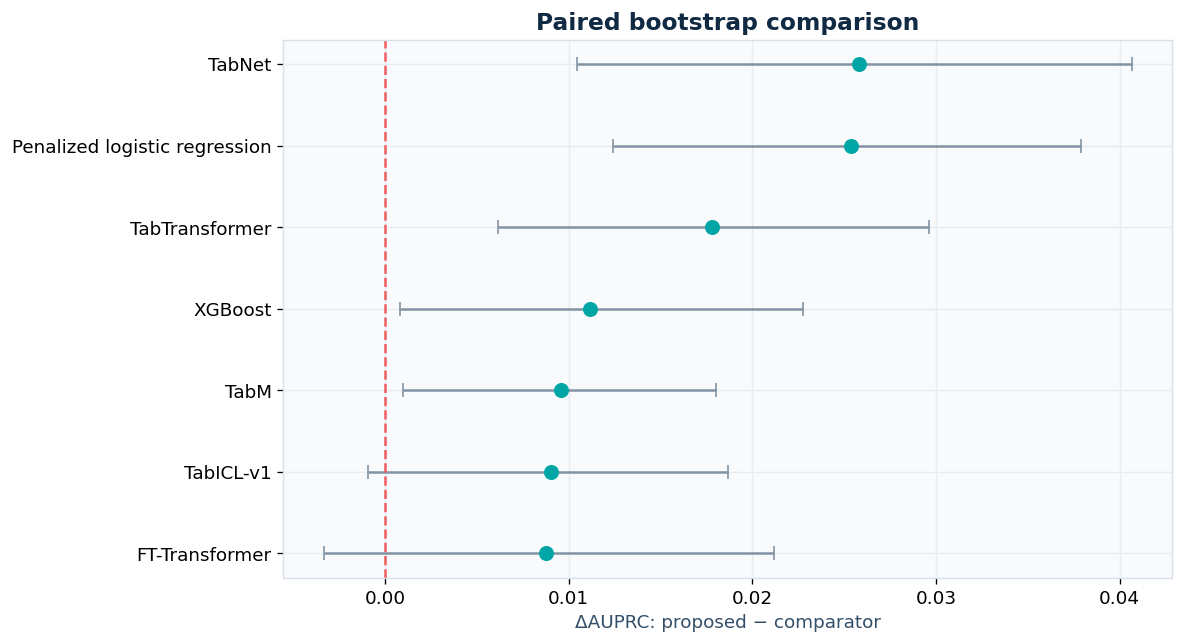

In [ ]:
def holm_adjust(pvalues):
    pvalues = np.asarray(pvalues, float)
    order = np.argsort(pvalues)
    adjusted = np.empty(len(pvalues), float)
    running = 0.0
    for rank, idx in enumerate(order):
        value = (len(pvalues) - rank) * pvalues[idx]
        running = max(running, value)
        adjusted[idx] = min(running, 1.0)
    return adjusted

comparison_rows = []
rng_pair = np.random.default_rng(RANDOM_STATE + 1200)
for comparator in [name for name in OOF if name != PRIMARY]:
    delta_ap = []
    delta_auc = []
    delta_brier = []
    for _ in range(N_BOOT):
        idx = stratified_bootstrap_indices(y, rng_pair)
        delta_ap.append(average_precision_score(y[idx], OOF[PRIMARY][idx]) - average_precision_score(y[idx], OOF[comparator][idx]))
        delta_auc.append(roc_auc_score(y[idx], OOF[PRIMARY][idx]) - roc_auc_score(y[idx], OOF[comparator][idx]))
        delta_brier.append(brier_score_loss(y[idx], OOF[comparator][idx]) - brier_score_loss(y[idx], OOF[PRIMARY][idx]))
    delta_ap = np.asarray(delta_ap)
    delta_auc = np.asarray(delta_auc)
    delta_brier = np.asarray(delta_brier)
    p_ap = 2 * min(np.mean(delta_ap <= 0), np.mean(delta_ap >= 0))
    comparison_rows.append({
        'Comparator': comparator,
        'ΔAUPRC': average_precision_score(y, OOF[PRIMARY]) - average_precision_score(y, OOF[comparator]),
        'ΔAUPRC low': np.quantile(delta_ap,.025),
        'ΔAUPRC high': np.quantile(delta_ap,.975),
        'ΔAUPRC 95% CI': f'[{np.quantile(delta_ap,.025):.3f}, {np.quantile(delta_ap,.975):.3f}]',
        'p_raw': max(p_ap, 1 / N_BOOT),
        'ΔAUROC': roc_auc_score(y, OOF[PRIMARY]) - roc_auc_score(y, OOF[comparator]),
        'ΔAUROC 95% CI': f'[{np.quantile(delta_auc,.025):.3f}, {np.quantile(delta_auc,.975):.3f}]',
        'ΔBrier other−proposed': brier_score_loss(y, OOF[comparator]) - brier_score_loss(y, OOF[PRIMARY]),
        'ΔBrier 95% CI': f'[{np.quantile(delta_brier,.025):.3f}, {np.quantile(delta_brier,.975):.3f}]',
    })
paired_results = pd.DataFrame(comparison_rows)
paired_results['p_Holm'] = holm_adjust(paired_results.p_raw.values)
display(styled_table(paired_results[['Comparator','ΔAUPRC','ΔAUPRC 95% CI','p_raw','p_Holm','ΔAUROC','ΔAUROC 95% CI','ΔBrier other−proposed','ΔBrier 95% CI']], 'ΔAUPRC', 4))

forest = paired_results.sort_values('ΔAUPRC')
fig, ax = plt.subplots(figsize=(10, 5.5))
ypos = np.arange(len(forest))
ax.errorbar(forest['ΔAUPRC'], ypos,
            xerr=[forest['ΔAUPRC']-forest['ΔAUPRC low'], forest['ΔAUPRC high']-forest['ΔAUPRC']],
            fmt='o', color=TEAL, ecolor=GREY, capsize=4, markersize=8)
ax.axvline(0, ls='--', color=CORAL)
ax.set_yticks(ypos, forest.Comparator)
ax.set(xlabel='ΔAUPRC: proposed − comparator', title='Paired bootstrap comparison')
save_show(fig, 'stage11_paired_forest')

## Stage 12 — Class-Conditional Conformal Triage

,Metric,Estimate
0,Marginal coverage,0.9333
1,Negative-class coverage,0.9058
2,Positive-class coverage,0.9537
3,Conformal referral rate,0.4677
4,Reliability referral rate,0.1903
5,Total referral rate,0.4853
6,Singleton rate,0.5148
7,Singleton accuracy,0.8776
8,Singleton balanced accuracy,0.8629
9,Singleton sensitivity,0.9260


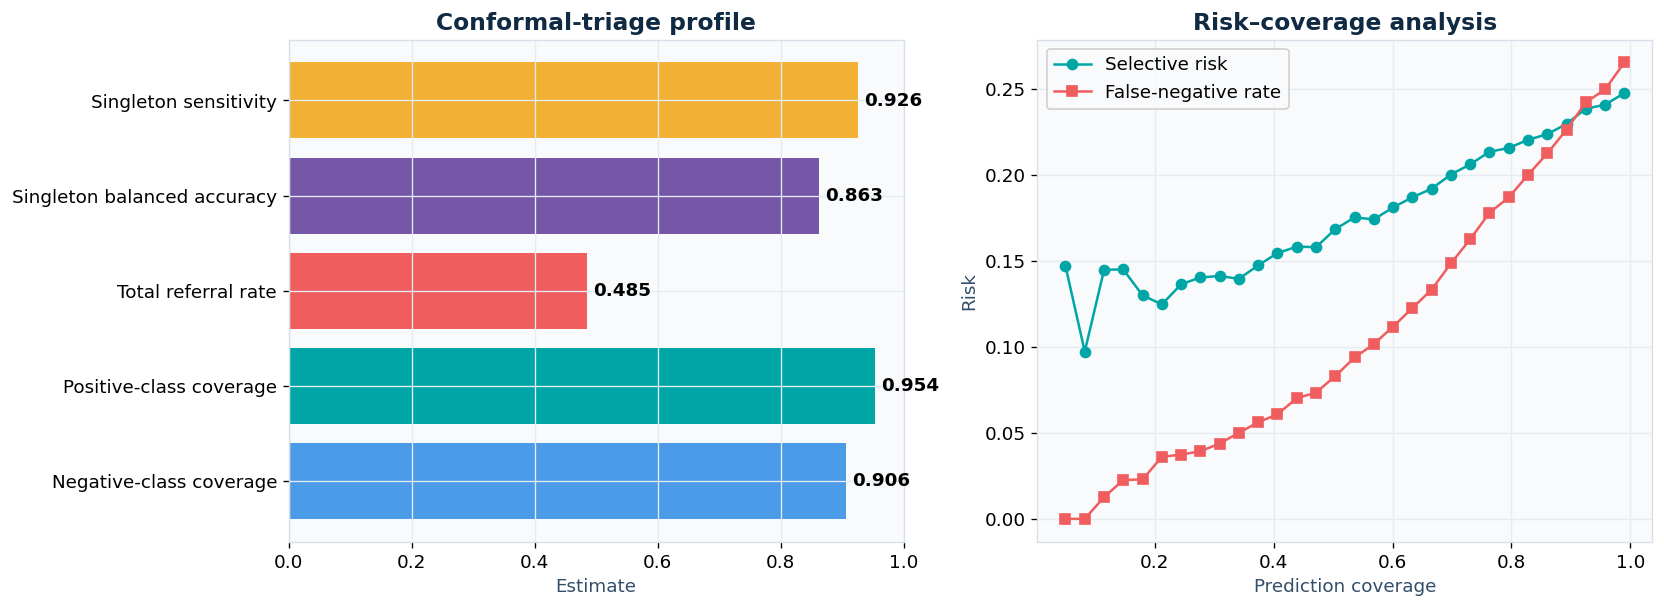

In [ ]:
triage = TRIAGE_RECORDS.copy()
triage['covered'] = np.where(triage.y.eq(0), triage.include_negative, triage.include_positive)
triage['singleton_correct'] = triage.decision.eq(triage.y) & ~triage.referred

triage_summary = pd.DataFrame({
    'Metric': [
        'Marginal coverage', 'Negative-class coverage', 'Positive-class coverage',
        'Conformal referral rate', 'Reliability referral rate', 'Total referral rate',
        'Singleton rate', 'Singleton accuracy', 'Singleton balanced accuracy',
        'Singleton sensitivity', 'Singleton specificity'
    ],
    'Estimate': [
        triage.covered.mean(),
        triage.loc[triage.y.eq(0), 'covered'].mean(),
        triage.loc[triage.y.eq(1), 'covered'].mean(),
        triage.conformal_referred.mean(),
        triage.reliability_referred.mean(),
        triage.referred.mean(),
        (~triage.referred).mean(),
        triage.loc[~triage.referred, 'singleton_correct'].mean(),
        balanced_accuracy_score(triage.loc[~triage.referred, 'y'], triage.loc[~triage.referred, 'decision']) if (~triage.referred).sum() and triage.loc[~triage.referred,'y'].nunique()==2 else np.nan,
        np.mean(triage.loc[triage.y.eq(1) & ~triage.referred, 'decision'].eq(1)) if (triage.y.eq(1) & ~triage.referred).sum() else np.nan,
        np.mean(triage.loc[triage.y.eq(0) & ~triage.referred, 'decision'].eq(0)) if (triage.y.eq(0) & ~triage.referred).sum() else np.nan,
    ]
})
display(styled_table(triage_summary, 'Estimate', 4))

coverage_grid = []
threshold_for_risk = float(np.median(MODEL_DIAGNOSTICS[PRIMARY].threshold))
for cutoff in np.quantile(triage.uncertainty, np.linspace(.05, .99, 30)):
    accepted = triage.uncertainty <= cutoff
    if accepted.sum() < 20 or triage.loc[accepted, 'y'].nunique() < 2:
        continue
    prediction = (triage.loc[accepted, 'probability'] >= threshold_for_risk).astype(int)
    met = threshold_metrics(triage.loc[accepted, 'y'].to_numpy(), prediction.to_numpy())
    coverage_grid.append({
        'Coverage': accepted.mean(),
        'Selective risk': 1 - met['Balanced accuracy'],
        'Sensitivity': met['Sensitivity'],
    })
risk_coverage = pd.DataFrame(coverage_grid).sort_values('Coverage')

fig, axes = plt.subplots(1, 2, figsize=(14, 5.2))
metrics_plot = triage_summary[triage_summary.Metric.isin(['Negative-class coverage','Positive-class coverage','Total referral rate','Singleton balanced accuracy','Singleton sensitivity'])]
axes[0].barh(metrics_plot.Metric, metrics_plot.Estimate, color=[SKY,TEAL,CORAL,PURPLE,GOLD])
axes[0].set(xlim=(0,1), xlabel='Estimate', title='Conformal-triage profile')
for p, v in zip(axes[0].patches, metrics_plot.Estimate):
    axes[0].text(v+.01, p.get_y()+p.get_height()/2, f'{v:.3f}', va='center', weight='bold')
axes[1].plot(risk_coverage.Coverage, risk_coverage['Selective risk'], marker='o', color=TEAL, label='Selective risk')
axes[1].plot(risk_coverage.Coverage, 1-risk_coverage.Sensitivity, marker='s', color=CORAL, label='False-negative rate')
axes[1].set(xlabel='Prediction coverage', ylabel='Risk', title='Risk–coverage analysis')
axes[1].legend()
save_show(fig, 'stage12_conformal_triage')

## Stage 13 — Decision-Curve Analysis

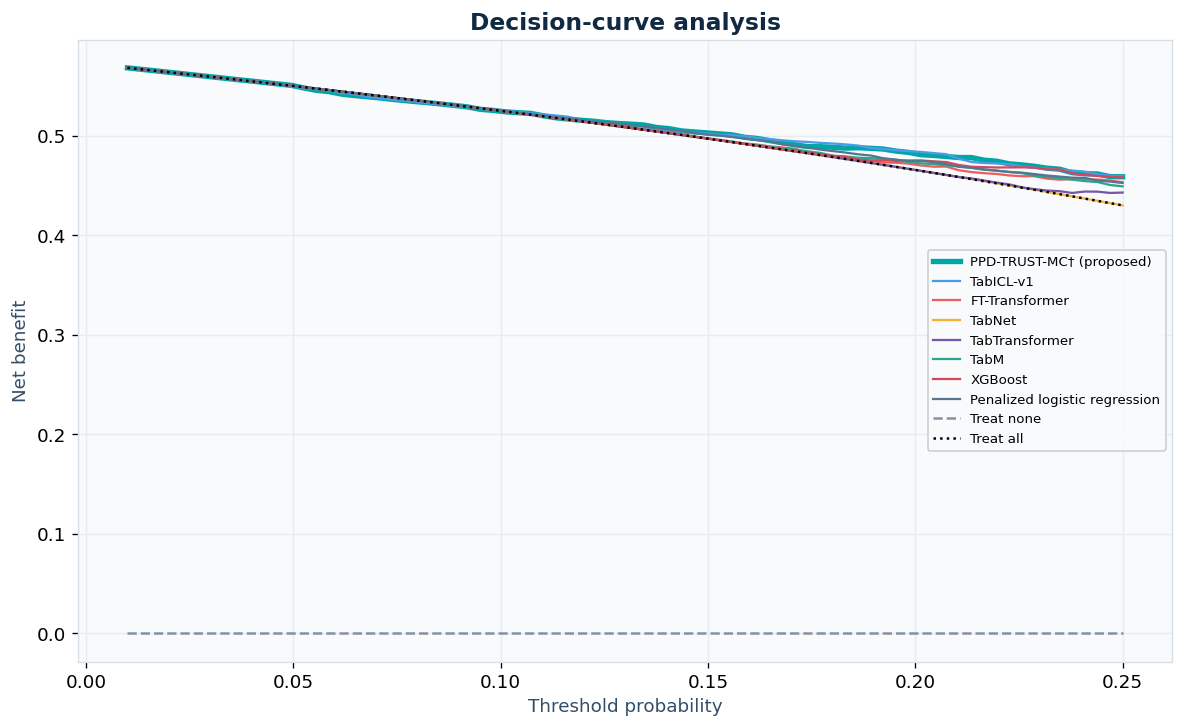

In [ ]:
def net_benefit(y_true, probability, threshold):
    predicted = probability >= threshold
    tp = np.sum(predicted & (y_true == 1))
    fp = np.sum(predicted & (y_true == 0))
    n = len(y_true)
    return tp / n - fp / n * threshold / (1 - threshold)

threshold_grid = np.linspace(.01, .25, 80)
fig, ax = plt.subplots(figsize=(10, 6.2))
for idx, (name, probability) in enumerate(OOF.items()):
    values = [net_benefit(y, probability, threshold) for threshold in threshold_grid]
    ax.plot(threshold_grid, values, lw=3.2 if name == PRIMARY else 1.35,
            color=PALETTE[idx % len(PALETTE)], label=name)
prevalence = y.mean()
treat_all = prevalence - (1 - prevalence) * threshold_grid / (1 - threshold_grid)
ax.plot(threshold_grid, np.zeros_like(threshold_grid), '--', color=GREY, label='Treat none')
ax.plot(threshold_grid, treat_all, ':', color='black', label='Treat all')
ax.set(xlabel='Threshold probability', ylabel='Net benefit', title='Decision-curve analysis')
ax.legend(fontsize=8)
save_show(fig, 'stage13_decision_curve')

## Stage 14 — Ablation Study

In [ ]:
if RUN_EXTENDED_ANALYSES:
    ABLATIONS = OrderedDict([
        ('TabPFN-3 full', make_trust_mc(use_core=False, use_xgboost=False, use_logistic=False, use_counterfactual=False, use_reliability=False)),
        ('TabPFN-3 full + stable core', make_trust_mc(use_xgboost=False, use_logistic=False, use_counterfactual=False, use_reliability=False)),
        ('Add XGBoost expert to fixed median', make_trust_mc(use_logistic=False, use_counterfactual=False, use_reliability=False)),
        ('Add logistic expert to fixed median', make_trust_mc(use_logistic=True, use_counterfactual=False, use_reliability=False)),
        ('PPD-TRUST-MC', make_trust_mc(use_counterfactual=True, use_reliability=True)),
    ])
    ABLATION_OOF, _, _, _, ABLATION_ERRORS = run_nested_cv(
        Xm, y, ABLATIONS, repeats=ABLATION_REPEATS, folds=OUTER_FOLDS,
        checkpoint_path=RESULT_DIR / 'ppd_trust_mc_tabpfn3_fixed_median_authenticated_ablation.pkl'
    )
    ablation_rows = []
    for name, probability in ABLATION_OOF.items():
        ablation_rows.append({
            'Variant': name,
            'AUROC': roc_auc_score(y, probability),
            'AUPRC': average_precision_score(y, probability),
            'Brier': brier_score_loss(y, probability),
            'ECE': expected_calibration_error(y, probability),
        })
    ablation_results = pd.DataFrame(ablation_rows).sort_values('AUPRC', ascending=False)
    display(styled_table(ablation_results, 'AUPRC', 4))

    baseline_ap = float(ablation_results.loc[ablation_results.Variant.eq('TabPFN-3 full'), 'AUPRC'].iloc[0])
    plot_ablation = ablation_results.copy()
    plot_ablation['ΔAUPRC vs TabPFN-3 full'] = plot_ablation.AUPRC - baseline_ap
    fig, axes = plt.subplots(1, 2, figsize=(14, 5.2))
    axes[0].barh(plot_ablation.Variant, plot_ablation['ΔAUPRC vs TabPFN-3 full'],
                 color=[CORAL if v=='PPD-TRUST-MC' else SKY for v in plot_ablation.Variant])
    axes[0].axvline(0, color=GREY, ls='--')
    axes[0].set(xlabel='ΔAUPRC', title='Progressive discrimination gain')
    axes[1].plot(plot_ablation.Variant, plot_ablation.Brier, marker='o', label='Brier', color=TEAL)
    axes[1].plot(plot_ablation.Variant, plot_ablation.ECE, marker='s', label='ECE', color=GOLD)
    axes[1].tick_params(axis='x', rotation=30)
    axes[1].set(title='Ablation calibration profile')
    axes[1].legend()
    save_show(fig, 'stage14_ablation')

## Stage 15 — Robustness Analysis

In [ ]:
def _apply_stress(frame, stress, level, rng):
    out = frame.copy()
    if stress == 'Missingness' and level > 0:
        mask = rng.random(out.shape) < level
        out = out.mask(mask)
    elif stress == 'Numeric noise':
        numeric_columns = [c for c in out.columns if pd.to_numeric(out[c], errors='coerce').notna().mean() >= .80]
        for column in numeric_columns:
            values = pd.to_numeric(out[column], errors='coerce')
            scale = float(values.std(skipna=True))
            if np.isfinite(scale) and scale > 0:
                out[column] = values + rng.normal(0, level*scale, len(values))
    return out


def run_robustness_cv(Xd, yv, estimator, conditions, seeds, folds=5, checkpoint_path=None):
    cp = Path(checkpoint_path) if checkpoint_path else None
    signature = hashlib.sha256(repr((conditions, seeds, folds, estimator.get_params(deep=True))).encode()).hexdigest()
    state = {'signature':signature, 'predictions':{}, 'done':set()}
    if cp is not None and cp.exists():
        loaded = pickle.load(open(cp,'rb'))
        if loaded.get('signature') == signature:
            state = loaded
    for stress, level in conditions:
        for seed in seeds:
            key = (stress, float(level), int(seed))
            if key not in state['predictions']:
                state['predictions'][key] = np.full(len(yv), np.nan, float)
            splitter = StratifiedKFold(folds, shuffle=True, random_state=seed)
            for fold, (train_idx, test_idx) in enumerate(splitter.split(Xd, yv)):
                job = (stress, float(level), int(seed), fold)
                if job in state['done']:
                    continue
                fitted = clone(estimator).fit(Xd.iloc[train_idx], yv[train_idx])
                rng = np.random.default_rng(seed*1000 + fold*31 + int(level*10000))
                X_test = _apply_stress(Xd.iloc[test_idx], stress, level, rng)
                state['predictions'][key][test_idx] = fitted.predict_proba(X_test)[:,1]
                state['done'].add(job)
                if cp is not None:
                    cp.parent.mkdir(parents=True, exist_ok=True)
                    pickle.dump(state, open(cp,'wb'), pickle.HIGHEST_PROTOCOL)
                del fitted
                gc.collect()
    rows = []
    for key, probability in state['predictions'].items():
        if np.isnan(probability).any():
            continue
        stress, level, seed = key
        rows.append({
            'Stress test': stress, 'Level': level, 'Seed': seed,
            'AUROC': roc_auc_score(yv, probability),
            'AUPRC': average_precision_score(yv, probability),
            'Brier': brier_score_loss(yv, probability),
        })
    return pd.DataFrame(rows)

if RUN_EXTENDED_ANALYSES:
    conditions = [('Missingness', v) for v in [0.0,.10,.20,.30]] + [('Numeric noise',v) for v in [.25,.50,1.00]]
    robustness_raw = run_robustness_cv(
        Xm, y, make_trust_mc(), conditions, ROBUSTNESS_SEEDS, OUTER_FOLDS,
        RESULT_DIR / 'ppd_trust_mc_tabpfn3_fixed_median_authenticated_robustness.pkl'
    )
    robustness_results = robustness_raw.groupby(['Stress test','Level'], as_index=False).agg(
        AUROC=('AUROC','mean'), AUROC_SD=('AUROC','std'),
        AUPRC=('AUPRC','mean'), AUPRC_SD=('AUPRC','std'),
        Brier=('Brier','mean'), Brier_SD=('Brier','std'),
    )
    display(styled_table(robustness_results, 'AUPRC', 4))

    fig, axes = plt.subplots(1, 2, figsize=(14, 5.2))
    for stress, color in [('Missingness',TEAL),('Numeric noise',CORAL)]:
        part = robustness_results[robustness_results['Stress test'].eq(stress)]
        axes[0].errorbar(part.Level, part.AUROC, yerr=part.AUROC_SD.fillna(0), marker='o', capsize=4, label=stress, color=color)
        axes[1].errorbar(part.Level, part.AUPRC, yerr=part.AUPRC_SD.fillna(0), marker='o', capsize=4, label=stress, color=color)
    axes[0].set(xlabel='Stress level', ylabel='AUROC', title='Robustness of ranking')
    axes[1].set(xlabel='Stress level', ylabel='AUPRC', title='Robustness of positive-class retrieval')
    axes[0].legend(); axes[1].legend()
    save_show(fig, 'stage15_robustness')

## Stage 16 — Secondary EPDS Outcome and Subgroup Evaluation

In [ ]:
from sklearn.metrics import cohen_kappa_score

# --- Secondary outcome: does the PHQ-9-trained model also flag EPDS-defined depression? ---
epds_rows = []
for label, target in [('Primary: PHQ-9 >= 10', y), ('Secondary: EPDS >= 13', y_epds)]:
    probability = OOF[PRIMARY]
    epds_rows.append({
        'Outcome': label,
        'Prevalence': float(target.mean()),
        'AUROC': roc_auc_score(target, probability),
        'AUPRC': average_precision_score(target, probability),
        'Brier': brier_score_loss(target, probability),
    })
epds_summary = pd.DataFrame(epds_rows)
label_kappa = float(cohen_kappa_score(y, y_epds))
print(f'PHQ-9 vs EPDS label agreement (Cohen kappa): {label_kappa:.3f}')
display(styled_table(epds_summary, 'AUPRC', 4))

# --- Subgroup discrimination on PPD_dataset_v2 predictors ---
subgroup_specs = OrderedDict()
if 'Age' in df.columns:
    subgroup_specs['Maternal age'] = pd.cut(pd.to_numeric(df['Age'], errors='coerce'),
                                             [0, 24, 29, 34, 100],
                                             labels=['<=24', '25-29', '30-34', '35+'])
for label, column in [('Residence', 'Residence'), ('Education', 'Education Level'),
                      ('Marital status', 'Marital status'), ('Family type', 'Family type')]:
    if column in df.columns:
        subgroup_specs[label] = df[column].astype(str)

subgroup_rows = []
rng_sub = np.random.default_rng(RANDOM_STATE + 8000)
for variable, values in subgroup_specs.items():
    for level in pd.Series(values).dropna().unique():
        mask = np.asarray(values == level)
        if mask.sum() < 50 or y[mask].sum() < 8 or (1 - y[mask]).sum() < 8:
            continue
        local_y = y[mask]
        local_p = OOF[PRIMARY][mask]
        boots = [roc_auc_score(local_y[idx], local_p[idx])
                 for idx in (stratified_bootstrap_indices(local_y, rng_sub) for _ in range(min(600, N_BOOT)))]
        met = threshold_metrics(local_y, THRESHOLD_PREDICTIONS[PRIMARY][mask])
        subgroup_rows.append({
            'Subgroup': f'{variable}: {level}', 'n': int(mask.sum()),
            'positive': int(local_y.sum()), 'Prevalence': float(local_y.mean()),
            'AUROC': roc_auc_score(local_y, local_p),
            'AUROC low': np.quantile(boots, .025), 'AUROC high': np.quantile(boots, .975),
            'AUPRC': average_precision_score(local_y, local_p),
            'Brier': brier_score_loss(local_y, local_p),
            'Sensitivity': met['Sensitivity'], 'Specificity': met['Specificity'],
        })
subgroup_results = pd.DataFrame(subgroup_rows).sort_values('AUROC')
display(styled_table(subgroup_results, 'AUROC', 4))

fig, axes = plt.subplots(1, 2, figsize=(16, max(5, .40 * len(subgroup_results))))
ypos = np.arange(len(subgroup_results))
axes[0].errorbar(subgroup_results.AUROC, ypos,
                 xerr=[subgroup_results.AUROC - subgroup_results['AUROC low'],
                       subgroup_results['AUROC high'] - subgroup_results.AUROC],
                 fmt='o', color=TEAL, ecolor=GREY, capsize=3)
axes[0].set_yticks(ypos, subgroup_results.Subgroup)
axes[0].set(xlabel='AUROC with 95% CI', title='Subgroup discrimination')
axes[1].scatter(subgroup_results.Prevalence, subgroup_results.AUPRC,
                s=np.maximum(subgroup_results.n, 50), c=subgroup_results.Brier,
                cmap='viridis', alpha=.85, edgecolor='white')
for _, row in subgroup_results.iterrows():
    axes[1].text(row.Prevalence, row.AUPRC, row.Subgroup.split(':')[0], fontsize=7, alpha=.75)
axes[1].set(xlabel='Subgroup prevalence', ylabel='AUPRC', title='Prevalence-aware subgroup profile')
save_show(fig, 'stage16_subgroup_evaluation')


## Stage 17 — External Validation: LTM III National (Harmonized Cross-National Transportability)



In [ ]:
transportability_results = pd.DataFrame()
if not national_available:
    print('LTM III national not available; external validation skipped.')
else:
    import re as _re
    national = pd.read_csv(NATIONAL_PATH, sep='\t', low_memory=False)

    # ---- Shared harmonized schema (edit the maps below against the LTM codebook) ----
    HARMONIZED = ['age_band', 'education', 'income', 'marital', 'parity',
                  'cesarean', 'breastfed', 'planned']

    def _norm(series):
        return series.astype(str).str.strip().str.lower()

    def _ppd_harmonized(frame):
        edu = {'primary school': 1, 'high school': 2, 'college': 2, 'university': 3}
        inc = {'less than 5000': 1, '5000 to 10000': 2, '10000 to 20000': 3,
               '20000 to 30000': 4, 'more than 30000': 5}
        par = {'one': 1, 'two': 2, 'more than two': 3}
        H = pd.DataFrame(index=frame.index)
        H['age_band'] = pd.cut(pd.to_numeric(frame['Age'], errors='coerce'),
                               [0, 24, 29, 34, 39, 200], labels=[1, 2, 3, 4, 5]).astype('float')
        H['education'] = _norm(frame['Education Level']).map(edu)
        H['income'] = _norm(frame['Husband’s monthly income']).map(inc)   # most complete income proxy
        H['marital'] = _norm(frame['Marital status']).map({'married': 1, 'divorced': 3})
        H['parity'] = _norm(frame['Total children']).map(par)
        H['cesarean'] = _norm(frame['Mode of delivery']).map({'normal delivery': 0, 'caesarean section': 1})
        H['breastfed'] = _norm(frame['Breastfeed']).map({'yes': 1, 'no': 0})
        H['planned'] = _norm(frame['Pregnancy plan']).map({'yes': 1, 'no': 0})
        return H[HARMONIZED].astype(float)

    def _decode_onehot(frame, prefix):
        cols = sorted([c for c in frame.columns if _re.match(prefix + r'_\d+$', c)],
                      key=lambda c: int(c.rsplit('_', 1)[1]))
        if not cols:
            return pd.Series(np.nan, index=frame.index)
        block = frame[cols].apply(pd.to_numeric, errors='coerce').fillna(0).to_numpy()
        level = block.argmax(1) + 1.0
        level[block.sum(1) == 0] = np.nan
        return pd.Series(level, index=frame.index)

    def _ltm_harmonized(frame):
        E = pd.DataFrame(index=frame.index)
        E['age_band'] = _decode_onehot(frame, 'Age_of_Mother')
        E['education'] = _decode_onehot(frame, 'Education')
        E['income'] = _decode_onehot(frame, 'HH_Income')
        E['marital'] = np.where(_decode_onehot(frame, 'Marital_Status') == 1, 1, 3)
        E['parity'] = _decode_onehot(frame, 'No_of_Times_Given_Birth')
        birth = _decode_onehot(frame, 'Type_of_Birth')
        E['cesarean'] = np.where(np.isin(birth, [2, 4]), 1, 0).astype(float)
        feed = _decode_onehot(frame, 'Infant_Feeding')
        E['breastfed'] = np.where(feed == 1, 1, 0).astype(float)
        E['planned'] = np.where(_decode_onehot(frame, 'Pregnancy_Intendedness') == 1, 1, 0).astype(float)
        return E[HARMONIZED].astype(float)

    H_train = _ppd_harmonized(df)
    label = pd.to_numeric(national['Depression_Screener_S'], errors='coerce')
    keep = label.isin([1, 2]).to_numpy()
    H_ext = _ltm_harmonized(national).loc[keep].reset_index(drop=True)
    y_ext = (label[keep].reset_index(drop=True) == 2).astype(int).to_numpy()

    # Impute with training-cohort medians (no external-label leakage).
    medians = H_train.median()
    H_train_f = H_train.fillna(medians)
    H_ext_f = H_ext.fillna(medians)

    # Internal reference: harmonized-feature model, 5-fold CV on the primary cohort.
    internal_oof = np.zeros(len(y), float)
    for tr, te in StratifiedKFold(5, shuffle=True, random_state=RANDOM_STATE).split(H_train_f, y):
        internal_oof[te] = make_trust_mc().fit(H_train_f.iloc[tr], y[tr]).predict_proba(H_train_f.iloc[te])[:, 1]
    internal_auroc = roc_auc_score(y, internal_oof)
    internal_auprc = average_precision_score(y, internal_oof)

    # External transfer: fit on full primary cohort, apply to LTM.
    external_model = make_trust_mc().fit(H_train_f, y)
    p_ext = external_model.predict_proba(H_ext_f)[:, 1]
    intercept_ext, slope_ext = calibration_intercept_slope(y_ext, p_ext)
    conf_ext = external_model.predict_conformal(H_ext_f)
    covered = np.where(y_ext == 0, conf_ext['include_negative'], conf_ext['include_positive'])

    transportability_results = pd.DataFrame([
        {'Setting': 'Internal (primary, harmonized 8-feat CV)', 'N': len(y),
         'Prevalence': float(y.mean()), 'AUROC': internal_auroc, 'AUPRC': internal_auprc,
         'Brier': brier_score_loss(y, internal_oof), 'Cal. slope': np.nan, 'Pos. coverage': np.nan},
        {'Setting': 'External transfer (LTM III national)', 'N': len(y_ext),
         'Prevalence': float(y_ext.mean()), 'AUROC': roc_auc_score(y_ext, p_ext),
         'AUPRC': average_precision_score(y_ext, p_ext), 'Brier': brier_score_loss(y_ext, p_ext),
         'Cal. slope': slope_ext, 'Pos. coverage': float(covered[y_ext == 1].mean())},
    ])
    display(styled_table(transportability_results, 'AUROC', 4))

    fig, axes = plt.subplots(1, 2, figsize=(14, 5.4))
    fpr_i, tpr_i, _ = roc_curve(y, internal_oof)
    fpr_e, tpr_e, _ = roc_curve(y_ext, p_ext)
    axes[0].plot(fpr_i, tpr_i, color=TEAL, lw=2.6, label=f'Internal AUROC={internal_auroc:.3f}')
    axes[0].plot(fpr_e, tpr_e, color=CORAL, lw=2.6, label=f'External AUROC={roc_auc_score(y_ext, p_ext):.3f}')
    axes[0].plot([0, 1], [0, 1], '--', color=GREY)
    axes[0].set(xlabel='False positive rate', ylabel='True positive rate',
                title='Harmonized transportability: ROC')
    axes[0].legend()
    order = np.argsort(p_ext)
    bins = np.array_split(order, 10)
    axes[1].plot([np.mean(p_ext[b]) for b in bins if len(b)],
                 [np.mean(y_ext[b]) for b in bins if len(b)],
                 marker='o', color=CORAL, lw=2.4, label='External')
    axes[1].plot([0, 1], [0, 1], '--', color=GREY)
    axes[1].set(xlabel='Mean predicted probability', ylabel='Observed frequency',
                title=f'External calibration (slope={slope_ext:.2f})', xlim=(0, .6), ylim=(0, .6))
    axes[1].legend()
    save_show(fig, 'stage17_external_transportability')
    print('External validation complete. Endpoint differs (2-item screen vs PHQ-9); interpret as transportability.')


## Stage 18 — External Validation Summary and Interpretive Caveats

In [ ]:
external_status = pd.DataFrame({
    'Aspect': ['Primary cohort', 'Primary endpoint', 'External cohort', 'External endpoint',
               'Shared predictors', 'Harmonization', 'Interpretation'],
    'Detail': [
        'PPD_dataset_v2 (Bangladesh, N=%d)' % len(y),
        'PHQ-9 >= 10 (probable major depression)',
        'LTM III national (US)' if national_available else 'not available',
        'Depression_Screener_S (2-item screen)',
        '8 harmonized demographic/obstetric predictors',
        'Ordered one-hot decode; verify against LTM codebook',
        'Cross-national transportability, NOT identical-endpoint replication',
    ],
})
display(styled_table(external_status, precision=0))
print('Caveats to report in the manuscript:')
print(' - Different outcome instrument (2-item screen) and different population (US vs Bangladesh).')
print(' - Only 8 crude harmonized predictors transfer; the full 46-feature model is not transferable.')
print(' - LTM one-hot level meanings are assumed ordered pending codebook confirmation.')
print(' - Report this as a transportability probe supporting generalization, not external accuracy.')


## Stage 19 — Reliability and Feature Stability

In [ ]:
FINAL_MODEL = make_trust_mc().fit(Xm, y)

participant_reliability = TRIAGE_RECORDS.groupby('index', as_index=False).agg(
    y=('y','first'),
    probability=('probability','mean'),
    uncertainty=('uncertainty','mean'),
    referral_rate=('referred','mean'),
)
participant_reliability['Reliability quartile'] = pd.qcut(
    participant_reliability.uncertainty,
    4,
    labels=['Q1 lowest','Q2','Q3','Q4 highest'],
    duplicates='drop',
)
reliability_table = participant_reliability.groupby('Reliability quartile', observed=True).apply(
    lambda part: pd.Series({
        'n': len(part),
        'positive': int(part.y.sum()),
        'Prevalence': part.y.mean(),
        'AUROC': roc_auc_score(part.y, part.probability) if part.y.nunique() == 2 else np.nan,
        'AUPRC': average_precision_score(part.y, part.probability),
        'Brier': brier_score_loss(part.y, part.probability),
        'Mean uncertainty': part.uncertainty.mean(),
        'Referral rate': part.referral_rate.mean(),
    })
).reset_index()

display(styled_table(FINAL_MODEL.expert_table_, 'AUPRC', 4))
display(styled_table(reliability_table, 'Mean uncertainty', 4))

domain_sensitivity = FINAL_MODEL.domain_sensitivity(Xm.sample(min(500,len(Xm)), random_state=RANDOM_STATE))
display(styled_table(domain_sensitivity, 'Mean absolute shift', 4))

stable_core = FINAL_MODEL.experts_.get('TabPFN-3-stable-core')
stability_scores = stable_core.selector_.scores_.head(30).rename('Stability score').to_frame() if stable_core is not None else pd.DataFrame()
if len(stability_scores):
    display(styled_table(stability_scores.reset_index(names='Feature'), 'Stability score', 5))

fig, axes = plt.subplots(1, 3, figsize=(19, 5.8))
axes[0].bar(reliability_table['Reliability quartile'].astype(str), reliability_table.Prevalence, color=[SKY,TEAL,GOLD,CORAL])
axes[0].set(ylabel='Positive prevalence', title='Risk concentration by uncertainty')
axes[1].barh(domain_sensitivity.Domain, domain_sensitivity['Mean absolute shift'], color=PALETTE[:len(domain_sensitivity)])
axes[1].set(xlabel='Mean absolute probability shift', title='Clinical-domain sensitivity')
if len(stability_scores):
    top = stability_scores.head(15).sort_values('Stability score')
    axes[2].barh(top.index, top['Stability score'], color=PURPLE)
axes[2].set(xlabel='Stability score', title='Stable-core predictors')
save_show(fig, 'stage19_reliability_explanation')

## Stage 20 — Result Export

In [ ]:
discrimination.to_csv(RESULT_DIR / 'primary_discrimination.csv', index=False)
threshold_results.to_csv(RESULT_DIR / 'threshold_performance.csv', index=False)
calibration_results.to_csv(RESULT_DIR / 'calibration_results.csv', index=False)
paired_results.to_csv(RESULT_DIR / 'paired_comparisons.csv', index=False)
triage_summary.to_csv(RESULT_DIR / 'conformal_triage.csv', index=False)
TRIAGE_RECORDS.to_csv(RESULT_DIR / 'conformal_triage_records.csv', index=False)
epds_summary.to_csv(RESULT_DIR / 'epds_secondary_outcome.csv', index=False)
subgroup_results.to_csv(RESULT_DIR / 'subgroup_results.csv', index=False)
reliability_table.to_csv(RESULT_DIR / 'reliability_quartiles.csv', index=False)
domain_sensitivity.to_csv(RESULT_DIR / 'domain_sensitivity.csv', index=False)
FINAL_MODEL.expert_table_.to_csv(RESULT_DIR / 'expert_inner_performance.csv', index=False)
if len(stability_scores):
    stability_scores.to_csv(RESULT_DIR / 'feature_stability_scores.csv')
if 'ablation_results' in globals():
    ablation_results.to_csv(RESULT_DIR / 'ablation_results.csv', index=False)
if 'robustness_results' in globals():
    robustness_results.to_csv(RESULT_DIR / 'robustness_results.csv', index=False)
    robustness_raw.to_csv(RESULT_DIR / 'robustness_raw.csv', index=False)
if 'transportability_results' in globals() and len(transportability_results):
    transportability_results.to_csv(RESULT_DIR / 'transportability_results.csv', index=False)
if 'external_status' in globals():
    external_status.to_csv(RESULT_DIR / 'external_status.csv', index=False)

model_card = {
    'model': PRIMARY,
    'architecture': 'fixed median consensus without logistic stacking, gradient stacking, or route selection',
    'foundation_model': 'TabPFN-3',
    'foundation_version': 'ModelVersion.V3',
    'tabpfn_estimators': TABPFN_ESTIMATORS,
    'tabpfn_core_estimators': TABPFN_CORE_ESTIMATORS,
    'comparison_foundation_model': TABICL_BASELINE,
    'comparison_checkpoint': TABICL_CHECKPOINT,
    'consensus': FINAL_MODEL.consensus_method_,
    'expert_names': FINAL_MODEL.expert_names_,
    'calibration_accepted': FINAL_MODEL.calibration_accepted_,
    'threshold': FINAL_MODEL.threshold_,
    'q_negative': FINAL_MODEL.q_negative_,
    'q_positive': FINAL_MODEL.q_positive_,
    'reliability_cutoff': FINAL_MODEL.reliability_cutoff_,
    'inner_metrics': FINAL_MODEL.inner_metrics_,
    'primary_dataset': 'PPD_dataset_v2 (PHQ-9 >= 10)',
    'external_cohort': 'LTM III national (harmonized transportability)',
}
with open(RESULT_DIR / 'model_card.json', 'w', encoding='utf-8') as handle:
    json.dump(model_card, handle, indent=2)

files = sorted([p.name for p in RESULT_DIR.iterdir() if p.is_file()])
export_table = pd.DataFrame({'Exported file': files})
display(export_table)

fig, ax = plt.subplots(figsize=(10, 3.6))
ax.axis('off')
ax.add_patch(FancyBboxPatch((.08,.22),.84,.56,boxstyle='round,pad=.02,rounding_size=.04',
                            transform=ax.transAxes,facecolor=TEAL,edgecolor='white'))
ax.text(.50,.58,'PPD-TRUST-MC',ha='center',va='center',color='white',weight='bold',fontsize=20,transform=ax.transAxes)
ax.text(.50,.40,f'{len(files)} result files exported',ha='center',va='center',color='white',fontsize=13,transform=ax.transAxes)
ax.text(.50,.12,str(RESULT_DIR.resolve()),ha='center',va='center',color=NAVY,fontsize=10,transform=ax.transAxes)
save_show(fig, 'stage20_export_complete')